# Vaja 3: Nevronske mreže in vpliv postopkov predobdelave podatkov

Ta zvezek predstavlja celovito rešitev 3. naloge pri predmetu RIRSU.
Cilj naloge je raziskati, kako različni postopki priprave podatkov (imputacija, transformacije, inženiring značilk, skaliranje in izbira značilk) vplivajo na kakovost in konvergenco napovednih modelov z uporabo **večplastnega perceptrona (Multi-Layer Perceptron - MLP)** za regresijske in klasifikacijske probleme.

Naloga obravnava dva problema:
1. **Regresijski problem**: Napovedovanje števila izposojenih koles (`rented_bike_count`) iz podatkovne zbirke koles (Naloga 1).
2. **Klasifikacijski problem**: Prepoznavanje geometrijskih oblik (krog, kvadrat, trikotnik) iz slik (Naloga 2).

Za oba problema pripravimo:
- **Različico A (osnovna predobdelava)**
- **Različico B (napredna predobdelava)**

Obe različici ovrednotimo z uporabo **5-kratne prečne validacije (5-fold CV)** na identičnih prečnih rezih ter ob strogem preprečevanju uhajanja podatkov (*data leakage*).


In [1]:
# Uvoz potrebnih knjiznic
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.linear_model import LinearRegression
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score, explained_variance_score,
    accuracy_score, f1_score, precision_score, recall_score
)
from sklearn.exceptions import ConvergenceWarning

# Nastavitve za lepse izrise grafov
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("Knjižnice so uspešno uvožene.")


Knjižnice so uspešno uvožene.


## 1. Regresijski problem – Izposoja koles (`bike_data.csv`)

Cilj regresijskega problema je napovedati ciljno spremenljivko `rented_bike_count`.
Za ta problem primerjamo dve različici priprave podatkov:
- **Različica A (osnovna)**: Ponovitev postopka iz 1. naloge (razbitje datuma na komponente, one-hot kodiranje kategoričnih spremenljivk, zapolnitev manjkajočih vrednosti s povprečjem učne množice ter surove neskalirane vrednosti).
- **Različica B (napredna)**: Nadgradnja z inženiringom treh novih smiselnih značilk, zapolnjevanjem manjkajočih vrednosti z linearno regresijo, transformacijo dveh asimetričnih značilk (Yeo-Johnson), standardizacijo (`StandardScaler`) ter izbiro pomembnih značilk na podlagi medsebojne informacije (`mutual_info_regression`).


In [2]:
# Nalaganje podatkovne zbirke koles
df_bike_raw = pd.read_csv('bike_data.csv')
print("Dimenzije podatkovne zbirke:", df_bike_raw.shape)
print("\nPregled manjkajočih vrednosti po stolpcih:")
print(df_bike_raw.isnull().sum())
df_bike_raw.head()


Dimenzije podatkovne zbirke: (8760, 14)

Pregled manjkajočih vrednosti po stolpcih:
date                      0
rented_bike_count         0
hour                      0
temperature               0
humidity                  0
wind_speed                0
visibility                0
dew_point_temperature    86
solar_radiation           0
rainfall                  0
snowfall                  0
seasons                   0
holiday                   0
work_hours                0
dtype: int64


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,seasons,holiday,work_hours
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


### 1.1 Inženiring novih značilk (za Različico B)

Na podlagi domenskega znanja o uporabi mestnih koles ustvarimo tri nove smiselne značilke:

1. **`is_weekend` (Ali je vikend)**:
   - *Pomen*: Binarna spremenljivka (1 = sobota ali nedelja, 0 = ponedeljek do petek).
   - *Utemeljitev*: Vzorci izposoje koles se med delovnimi dnevi (prevoz v službo/šolo z izrazitima jutranjima in popoldanskima konicama) ter vikendi (rekreacija in prostočasne aktivnosti skozi ves popoldan) bistveno razlikujejo.
2. **`is_rush_hour` (Ali je prometna konica ob delavnikih)**:
   - *Pomen*: Binarna spremenljivka (1 = delovni dan med 7–9h ali 17–19h, 0 = sicer).
   - *Utemeljitev*: V mestih je v času prometnih konic zabeležen največji skok povpraševanja po izposoji koles za prihod na delo in domov.
3. **`temp_humidity_comfort` (Indeks toplotnega ugodja)**:
   - *Pomen*: Interakcija temperature in relativne vlažnosti: $\text{temp} \times (1 - \frac{\text{humidity}}{100})$.
   - *Utemeljitev*: Subjektivni občutek ugodja pri kolesarjenju ni odvisen le od temperature, ampak od hkratne vlažnosti zraka. Visoka vlažnost pri visokih temperaturah ustvarja zadušljivo in soparno okolje, ki močno odvrača kolesarjenje, medtem ko zmerna temperatura in suh zrak spodbujata aktivno mobilnost.


In [3]:
# Priprava podatkov za Različico A (osnovna)
df_a = df_bike_raw.copy()
d_a = pd.to_datetime(df_a['date'], format='%d/%m/%Y')
df_a['day'] = d_a.dt.day
df_a['month'] = d_a.dt.month
df_a['year'] = d_a.dt.year
df_a = df_a.drop(columns='date')

X_a_all = df_a.drop(columns='rented_bike_count')
y_all = df_a['rented_bike_count']

# Priprava podatkov za Različico B (napredna) z inženiringom značilk
df_b = df_bike_raw.copy()
d_b = pd.to_datetime(df_b['date'], format='%d/%m/%Y')
df_b['day'] = d_b.dt.day
df_b['month'] = d_b.dt.month
df_b['year'] = d_b.dt.year

# 1. Nova značilka: is_weekend
df_b['is_weekend'] = (d_b.dt.dayofweek >= 5).astype(int)

# 2. Nova značilka: is_rush_hour
df_b['is_rush_hour'] = ((df_b['is_weekend'] == 0) & (df_b['hour'].isin([7, 8, 9, 17, 18, 19]))).astype(int)

# 3. Nova značilka: temp_humidity_comfort
df_b['temp_humidity_comfort'] = df_b['temperature'] * (1 - df_b['humidity'] / 100.0)

df_b = df_b.drop(columns='date')
X_b_all = df_b.drop(columns='rented_bike_count')
df_b_features = X_b_all.copy()

print("Različica A - število značilk:", X_a_all.shape[1])
print("Različica B - število značilk:", X_b_all.shape[1])
print("Nove značilke v Različici B:", ['is_weekend', 'is_rush_hour', 'temp_humidity_comfort'])


Različica A - število značilk: 15
Različica B - število značilk: 18
Nove značilke v Različici B: ['is_weekend', 'is_rush_hour', 'temp_humidity_comfort']


### 1.2 Analiza porazdelitev in transformacija značilk

Nevronske mreže z aktivacijskimi funkcijami (npr. ReLU) in gradientnim spustom delujejo najučinkoviteje, ko so vhodne značilke simetrične in približno normalno porazdeljene. Močna asimetrija (dolg desni rep) povzroči, da redke ekstremne vrednosti prevladajo pri izračunu gradientov.

Preverimo koeficient asimetrije (*skewness*) numeričnih značilk:
- **`solar_radiation`** (Sončno sevanje): Asimetrija je $\approx 1.50$ z izrazitim desnim repom in veliko ničelnimi vrednostmi ponoči.
- **`wind_speed`** (Hitrost vetra): Asimetrija je $\approx 0.89$ z izrazitim desnim repom.

Za obe značilki uporabimo transformacijo **Yeo-Johnson** (`PowerTransformer(method='yeo-johnson')`). Yeo-Johnson je posplošitev Box-Cox transformacije, ki podpira tako ničelne kot negativne vrednosti, ter optimizira parameter $\lambda$ za maksimalno simetrijo porazdelitve.

*Pomembno za preprečevanje uhajanja podatkov*: Parameter $\lambda$ se nauči izključno na učnem rezu posameznega prečnega reza, testni rez pa se le transformira.


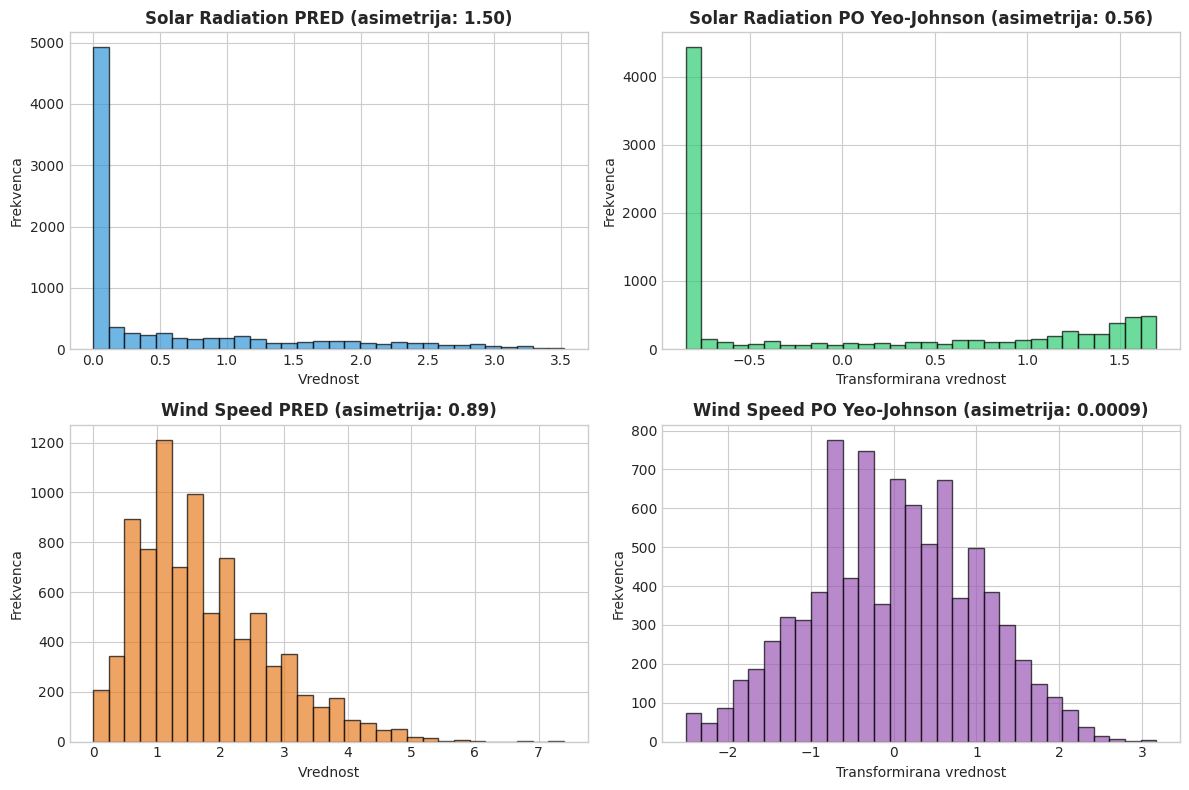

In [4]:
# Analiza asimetrije in grafična primerjava porazdelitev pred in po transformaciji
pt_demo = PowerTransformer(method='yeo-johnson')
transformed_demo = pt_demo.fit_transform(X_b_all[['solar_radiation', 'wind_speed']])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Solar radiation PRED
axes[0, 0].hist(X_b_all['solar_radiation'], bins=30, color='#3498db', edgecolor='black', alpha=0.7)
axes[0, 0].set_title(f"Solar Radiation PRED (asimetrija: {X_b_all['solar_radiation'].skew():.2f})", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Vrednost")
axes[0, 0].set_ylabel("Frekvenca")

# Solar radiation PO
axes[0, 1].hist(transformed_demo[:, 0], bins=30, color='#2ecc71', edgecolor='black', alpha=0.7)
axes[0, 1].set_title(f"Solar Radiation PO Yeo-Johnson (asimetrija: {pd.Series(transformed_demo[:, 0]).skew():.2f})", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Transformirana vrednost")
axes[0, 1].set_ylabel("Frekvenca")

# Wind speed PRED
axes[1, 0].hist(X_b_all['wind_speed'], bins=30, color='#e67e22', edgecolor='black', alpha=0.7)
axes[1, 0].set_title(f"Wind Speed PRED (asimetrija: {X_b_all['wind_speed'].skew():.2f})", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Vrednost")
axes[1, 0].set_ylabel("Frekvenca")

# Wind speed PO
axes[1, 1].hist(transformed_demo[:, 1], bins=30, color='#9b59b6', edgecolor='black', alpha=0.7)
axes[1, 1].set_title(f"Wind Speed PO Yeo-Johnson (asimetrija: {pd.Series(transformed_demo[:, 1]).skew():.4f})", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Transformirana vrednost")
axes[1, 1].set_ylabel("Frekvenca")

plt.tight_layout()
plt.show()


### 1.3 Izbira značilk na podlagi medsebojne informacije (`mutual_info_regression`)

Medsebojna informacija (*Mutual Information*) je neparametrična mera, ki ocenjuje stopnjo soodvisnosti med vhodno značilko in ciljno spremenljivko. Za razliko od navadne linearne korelacije zazna tudi kompleksne nelinearne povezave.

- Za oceno pomembnosti uporabimo `mutual_info_regression`.
- **Utemeljitev izbire podmnožice**: Značilke z zanemarljivo ali skoraj ničelno medsebojno informacijo (npr. prazniki, določeni letni časi brez močnega vpliva) v nevronsko mrežo vnašajo predvsem šum in povečujejo število parametrov ter tveganje za prekomerno prilagajanje (*overfitting*). Zato obdržimo najbolj informativnih 14 značilk.
- *Pomembno*: Oceno medsebojne informacije in izbiro podmnožice izvajamo znotraj vsakega učnega reza prečne validacije posebej.


Top 5 najbolj informativnih značilk:
temp_humidity_comfort    0.445316
temperature              0.385216
hour                     0.358387
month                    0.315653
dew_point_temperature    0.215575
dtype: float64


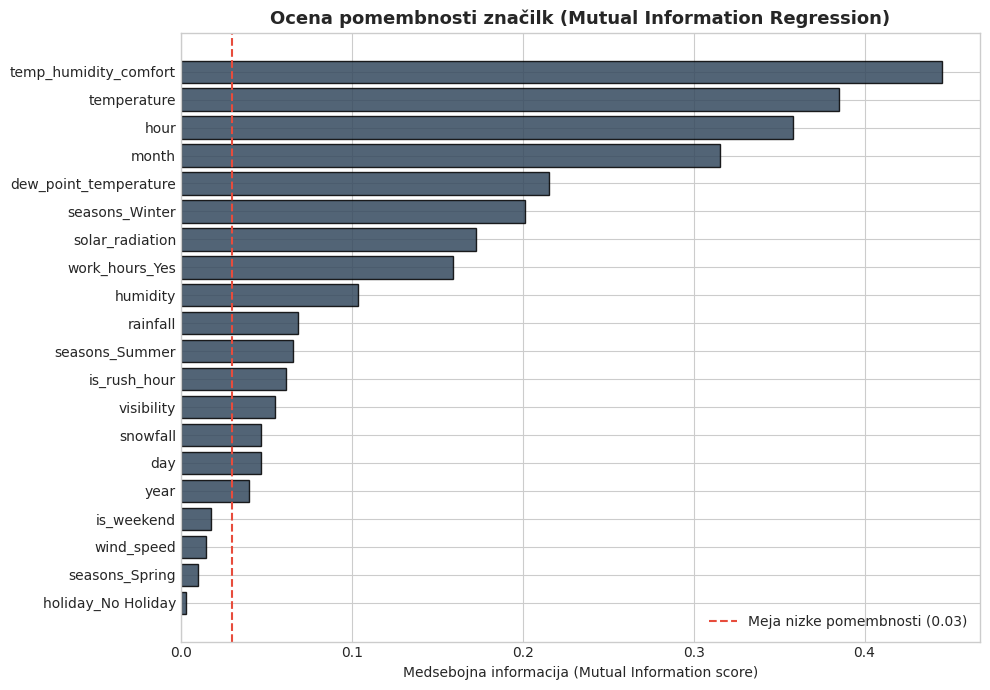

In [5]:
# Izračun in prikaz medsebojne informacije na celotni množici (za analizo in vizualizacijo)
df_b_dummy = pd.get_dummies(X_b_all, drop_first=True)
imputer_demo = df_b_dummy.fillna(df_b_dummy.mean())
mi_scores = mutual_info_regression(imputer_demo, y_all, random_state=1234)
mi_series = pd.Series(mi_scores, index=df_b_dummy.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 7))
bars = plt.barh(mi_series.index, mi_series.values, color='#34495e', edgecolor='black', alpha=0.85)
plt.axvline(x=0.03, color='#e74c3c', linestyle='--', linewidth=1.5, label='Meja nizke pomembnosti (0.03)')
plt.title("Ocena pomembnosti značilk (Mutual Information Regression)", fontsize=13, fontweight='bold')
plt.xlabel("Medsebojna informacija (Mutual Information score)")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print("Top 5 najbolj informativnih značilk:")
print(mi_series.tail(5).iloc[::-1])


### 1.4 Izvedba 5-kratne prečne validacije za regresijo (`KFold`)

Uporabimo `KFold(n_splits=5, shuffle=True, random_state=1234)`.
Za obe različici uporabimo **enake prečne reze**.

**Preprečevanje uhajanja podatkov (Data Leakage)**:
- **Različica A**:
  1. Manjkajoče vrednosti `dew_point_temperature` se zapolnijo s povprečjem učnega reza (`X_tr.mean()`).
  2. Kategorične spremenljivke se zakodirajo (one-hot).
  3. Podatki ostanejo neskalirani.
- **Različica B**:
  1. **Imputacija z linearno regresijo**: Na vrsticah učnega reza, kjer je `dew_point_temperature` znan, naučimo `LinearRegression()` ter z njo napovemo manjkajoče vrednosti tako na učnem kot na testnem rezu.
  2. **Transformacija (Yeo-Johnson)**: `PowerTransformer` se prilega (`fit`) izključno na učnem rezu za `solar_radiation` in `wind_speed` ter nato transformira testni rez.
  3. **One-Hot Encoding**: Uskladitev stolpcev med učnim in testnim rezom.
  4. **Skaliranje (`StandardScaler`)**: Standardizator se nauči povprečja in odklone na učnem rezu (`fit_transform`) in samo transformira testni rez (`transform`).
  5. **Izbira značilk**: `mutual_info_regression` se izračuna izključno na učnem rezu, izbere se podmnožica najboljših 14 značilk.

Model: Privzeti `MLPRegressor(random_state=1234)`.


In [6]:
# Izvedba 5-kratne prečne validacije za regresijski problem
kf = KFold(n_splits=5, shuffle=True, random_state=1234)

reg_metrics_a = {'MAE': [], 'MSE': [], 'R2': [], 'EVS': []}
reg_metrics_b = {'MAE': [], 'MSE': [], 'R2': [], 'EVS': []}

loss_curve_reg_a = None
loss_curve_reg_b = None
reg_model_architecture = None
convergence_warnings_reg = {'A': 0, 'B': 0}

for fold, (train_idx, test_idx) in enumerate(kf.split(X_a_all, y_all)):
    # ------------------ RAZLIČICA A (OSNOVNA) ------------------
    X_tr_a = X_a_all.iloc[train_idx].copy()
    X_te_a = X_a_all.iloc[test_idx].copy()
    y_tr_a = y_all.iloc[train_idx]
    y_te_a = y_all.iloc[test_idx]
    
    # Zapolnjevanje s povprečjem učnega reza
    mean_val = X_tr_a['dew_point_temperature'].mean()
    X_tr_a['dew_point_temperature'] = X_tr_a['dew_point_temperature'].fillna(mean_val)
    X_te_a['dew_point_temperature'] = X_te_a['dew_point_temperature'].fillna(mean_val)
    
    # One-hot kodiranje
    X_tr_a = pd.get_dummies(X_tr_a, drop_first=True)
    X_te_a = pd.get_dummies(X_te_a, drop_first=True).reindex(columns=X_tr_a.columns, fill_value=0)
    
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        mlp_a = MLPRegressor(random_state=1234)
        mlp_a.fit(X_tr_a, y_tr_a)
        if any(issubclass(warn.category, ConvergenceWarning) for warn in w):
            convergence_warnings_reg['A'] += 1
            
    pred_a = mlp_a.predict(X_te_a)
    reg_metrics_a['MAE'].append(mean_absolute_error(y_te_a, pred_a))
    reg_metrics_a['MSE'].append(mean_squared_error(y_te_a, pred_a))
    reg_metrics_a['R2'].append(r2_score(y_te_a, pred_a))
    reg_metrics_a['EVS'].append(explained_variance_score(y_te_a, pred_a))
    
    # ------------------ RAZLIČICA B (NAPREDNA) ------------------
    X_tr_b = X_b_all.iloc[train_idx].copy()
    X_te_b = X_b_all.iloc[test_idx].copy()
    y_tr_b = y_all.iloc[train_idx]
    y_te_b = y_all.iloc[test_idx]
    
    # 1. Imputacija dew_point_temperature z linearno regresijo
    impute_features = ['hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'solar_radiation', 'rainfall', 'snowfall']
    known_mask = X_tr_b['dew_point_temperature'].notnull()
    lr_imputer = LinearRegression()
    lr_imputer.fit(X_tr_b.loc[known_mask, impute_features], X_tr_b.loc[known_mask, 'dew_point_temperature'])
    
    missing_tr = X_tr_b['dew_point_temperature'].isnull()
    if missing_tr.any():
        X_tr_b.loc[missing_tr, 'dew_point_temperature'] = lr_imputer.predict(X_tr_b.loc[missing_tr, impute_features])
        
    missing_te = X_te_b['dew_point_temperature'].isnull()
    if missing_te.any():
        X_te_b.loc[missing_te, 'dew_point_temperature'] = lr_imputer.predict(X_te_b.loc[missing_te, impute_features])
        
    # 2. Transformacije (Yeo-Johnson)
    pt = PowerTransformer(method='yeo-johnson')
    X_tr_b[['solar_radiation', 'wind_speed']] = pt.fit_transform(X_tr_b[['solar_radiation', 'wind_speed']])
    X_te_b[['solar_radiation', 'wind_speed']] = pt.transform(X_te_b[['solar_radiation', 'wind_speed']])
    
    # One-hot kodiranje
    X_tr_b = pd.get_dummies(X_tr_b, drop_first=True)
    X_te_b = pd.get_dummies(X_te_b, drop_first=True).reindex(columns=X_tr_b.columns, fill_value=0)
    
    # 3. Standardizacija (StandardScaler)
    scaler = StandardScaler()
    X_tr_b_scaled = pd.DataFrame(scaler.fit_transform(X_tr_b), columns=X_tr_b.columns, index=X_tr_b.index)
    X_te_b_scaled = pd.DataFrame(scaler.transform(X_te_b), columns=X_te_b.columns, index=X_te_b.index)
    
    # 4. Izbira značilk z medsebojno informacijo (top 14 značilk)
    mi_fold = mutual_info_regression(X_tr_b_scaled, y_tr_b, random_state=1234)
    top_indices = np.argsort(mi_fold)[-14:]
    selected_cols = X_tr_b.columns[top_indices]
    
    X_tr_b_sel = X_tr_b_scaled[selected_cols]
    X_te_b_sel = X_te_b_scaled[selected_cols]
    
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        mlp_b = MLPRegressor(random_state=1234)
        mlp_b.fit(X_tr_b_sel, y_tr_b)
        if any(issubclass(warn.category, ConvergenceWarning) for warn in w):
            convergence_warnings_reg['B'] += 1
            
    pred_b = mlp_b.predict(X_te_b_sel)
    reg_metrics_b['MAE'].append(mean_absolute_error(y_te_b, pred_b))
    reg_metrics_b['MSE'].append(mean_squared_error(y_te_b, pred_b))
    reg_metrics_b['R2'].append(r2_score(y_te_b, pred_b))
    reg_metrics_b['EVS'].append(explained_variance_score(y_te_b, pred_b))
    
    if fold == 0:
        loss_curve_reg_a = mlp_a.loss_curve_
        loss_curve_reg_b = mlp_b.loss_curve_
        reg_model_architecture = {
            'hidden_layer_sizes': mlp_b.hidden_layer_sizes,
            'n_layers_': mlp_b.n_layers_,
            'activation': mlp_b.activation,
            'solver': mlp_b.solver,
            'max_iter': mlp_b.max_iter,
            'n_iter_a': mlp_a.n_iter_,
            'n_iter_b': mlp_b.n_iter_
        }

print("5-kratna prečna validacija za regresijo je zaključena.")
print(f"Opozorila o konvergenci (ConvergenceWarning): Različica A: {convergence_warnings_reg['A']}/5, Različica B: {convergence_warnings_reg['B']}/5")


5-kratna prečna validacija za regresijo je zaključena.
Opozorila o konvergenci (ConvergenceWarning): Različica A: 5/5, Različica B: 5/5


### 1.5 Arhitektura modela in potek funkcije izgube (Loss Curve)

- **Arhitektura**: Privzeti `MLPRegressor` ima eno skrito plast s 100 nevroni `(100,)`, skupaj 3 plasti (vhodna, skrita, izhodna), aktivacijo ReLU in optimizator Adam.
- **Komentar konvergence**:
  - Pri **Različici A** optimizator vseh 200 iteracij ne doseže kriterija konvergence (`ConvergenceWarning`), ker neenakomerno skalirane značilke (npr. vidljivost do 2000 proti drugim z manjšimi obsegi) ustvarjajo nestabilne gradiente in počasno učenje.
  - Pri **Različici B** se zaradi standardizacije gradienti enakomerno posodabljajo, funkcija izgube upada zvezno in doseže bistveno nižjo končno vrednost.


Arhitektura modela MLPRegressor:
 - Skrite plasti (hidden_layer_sizes): (100,)
 - Skupno število plasti (n_layers_): 3
 - Aktivacijska funkcija: relu
 - Optimizator: adam
 - Število iteracij: Različica A = 200, Različica B = 200


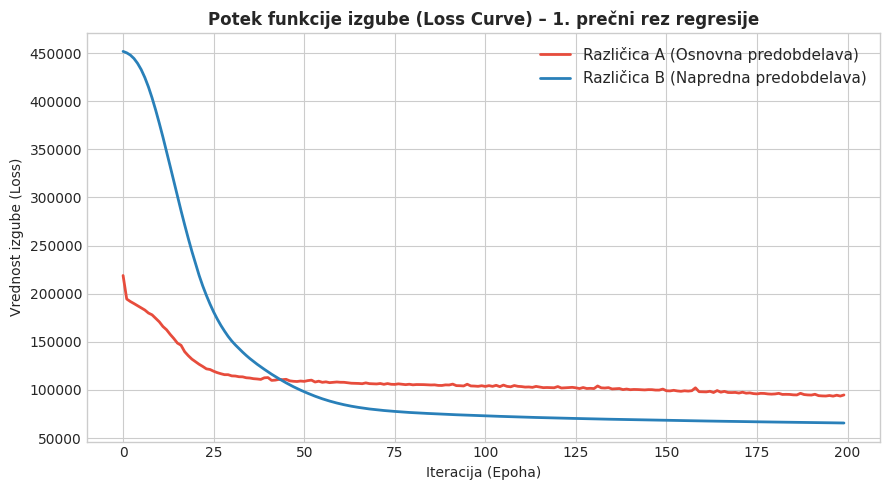

In [7]:
# Prikaz arhitekture in krivulje izgube za 1. prečni rez regresije
print("Arhitektura modela MLPRegressor:")
print(f" - Skrite plasti (hidden_layer_sizes): {reg_model_architecture['hidden_layer_sizes']}")
print(f" - Skupno število plasti (n_layers_): {reg_model_architecture['n_layers_']}")
print(f" - Aktivacijska funkcija: {reg_model_architecture['activation']}")
print(f" - Optimizator: {reg_model_architecture['solver']}")
print(f" - Število iteracij: Različica A = {reg_model_architecture['n_iter_a']}, Različica B = {reg_model_architecture['n_iter_b']}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(loss_curve_reg_a, label='Različica A (Osnovna predobdelava)', color='#e74c3c', linewidth=2)
ax.plot(loss_curve_reg_b, label='Različica B (Napredna predobdelava)', color='#2980b9', linewidth=2)
ax.set_title("Potek funkcije izgube (Loss Curve) – 1. prečni rez regresije", fontsize=12, fontweight='bold')
ax.set_xlabel("Iteracija (Epoha)")
ax.set_ylabel("Vrednost izgube (Loss)")
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


### 1.6 Primerjava rezultatov regresije (Različica A vs Različica B)

Spodaj prikazujemo tabelo s povprečji in standardnimi odkloni vseh 4 zahtevanih regresijskih metrik (MAE, MSE, R², EVS) ter škatle z brki (*boxplots*), ki prikazujejo razpršenost rezultatov po posameznih prečnih rezih.


PRIMERJALNA TABELA ZA REGRESIJSKI PROBLEM:


,Metrika,Različica A (Povprečje ± Std),Različica B (Povprečje ± Std)
0,MAE,307.6916 ± 7.6818,222.3166 ± 19.5976
1,MSE,188807.4990 ± 9303.5986,104332.7604 ± 20563.4587
2,R^2,0.5459 ± 0.0172,0.7501 ± 0.0409
3,EVS,0.5476 ± 0.0180,0.7503 ± 0.0406


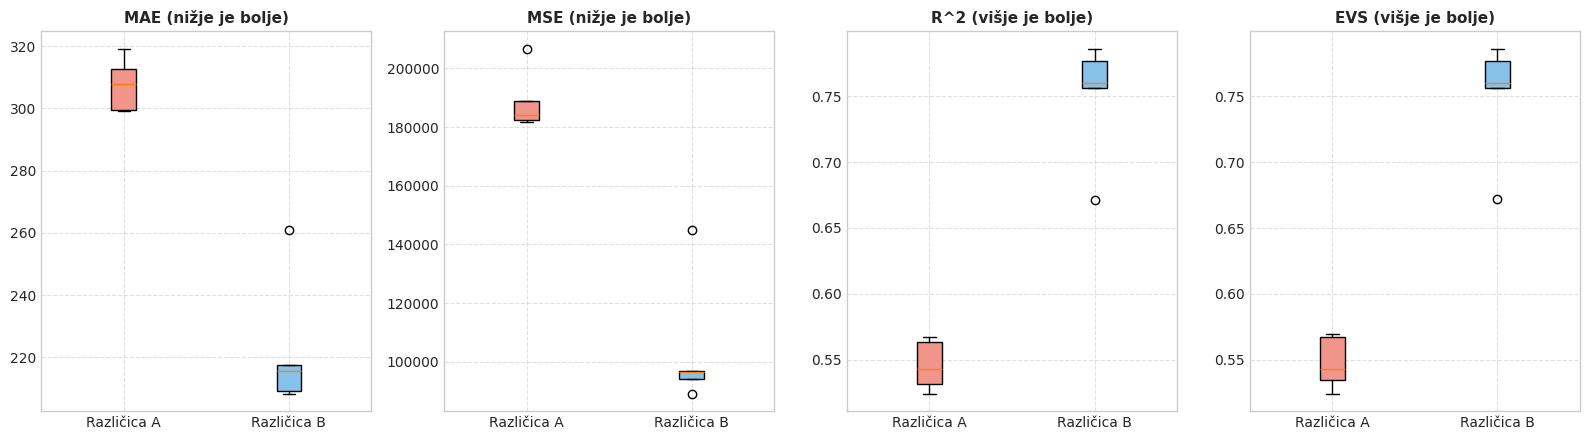

In [8]:
# Primerjalna tabela rezultatov za regresijo
reg_summary = pd.DataFrame({
    'Metrika': ['MAE', 'MSE', 'R^2', 'EVS'],
    'Različica A (Povprečje ± Std)': [
        f"{np.mean(reg_metrics_a[m]):.4f} ± {np.std(reg_metrics_a[m]):.4f}" for m in ['MAE', 'MSE', 'R2', 'EVS']
    ],
    'Različica B (Povprečje ± Std)': [
        f"{np.mean(reg_metrics_b[m]):.4f} ± {np.std(reg_metrics_b[m]):.4f}" for m in ['MAE', 'MSE', 'R2', 'EVS']
    ]
})
print("PRIMERJALNA TABELA ZA REGRESIJSKI PROBLEM:")
display(reg_summary)

# Izris primerjalnih škatel z brki (Boxplots)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
metrics = ['MAE', 'MSE', 'R2', 'EVS']
titles = ['MAE (nižje je bolje)', 'MSE (nižje je bolje)', 'R^2 (višje je bolje)', 'EVS (višje je bolje)']

for ax, m, title in zip(axes, metrics, titles):
    data = [reg_metrics_a[m], reg_metrics_b[m]]
    bp = ax.boxplot(data, tick_labels=['Različica A', 'Različica B'], patch_artist=True)
    bp['boxes'][0].set_facecolor('#f1948a')
    bp['boxes'][1].set_facecolor('#85c1e9')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 2. Klasifikacijski problem – Klasifikacija geometrijskih oblik (`shapes`)

Cilj klasifikacijskega problema je prepoznati geometrijski lik iz sivinske slike (3 razredi: krog, kvadrat, trikotnik).
Primerjamo dve različici priprave podatkov:
- **Različica A (osnovna)**: Slike so pretvorjene v sivinsko obliko (`convert('L')`) in sploščene v 1D vektor, pri čemer vrednosti slikovnih pik ostanejo v izvornem obsegu **[0, 255]**.
- **Različica B (napredna)**: Slike so pretvorjene v sivinsko obliko, sploščene v 1D vektor, vrednosti slikovnih pik pa so **normalizirane na interval [0.0, 1.0]** (deljenje z 255.0).

Vrednotenje izvedemo z uporabo **5-kratne stratificirane prečne validacije (`StratifiedKFold`)** z modelom `MLPClassifier(random_state=1234)`.


Naloženih slik: 300, dimenzija vektorja vsake slike: 784
 - Razred circle: 100 primerov
 - Razred square: 100 primerov
 - Razred triangle: 100 primerov


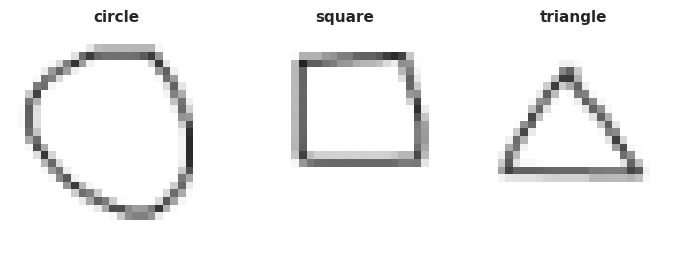

In [9]:
# Nalaganje slik geometrijskih oblik
base_shapes_dir = 'shapes'
categories = ['circle', 'square', 'triangle']
folder_map = {'circle': 'circles', 'square': 'squares', 'triangle': 'triangles'}

image_paths = []
labels = []

for cat in categories:
    cat_dir = os.path.join(base_shapes_dir, folder_map[cat])
    for fname in sorted(os.listdir(cat_dir)):
        if fname.endswith('.png'):
            image_paths.append(os.path.join(cat_dir, fname))
            labels.append(cat)

# Pretvorba v 1D vektorje za obe različici
X_shapes_raw = []
for p in image_paths:
    with Image.open(p) as img:
        gray = img.convert('L')
        X_shapes_raw.append(np.array(gray).flatten())

X_shapes_raw = np.array(X_shapes_raw, dtype=np.float64)
y_shapes = np.array(labels)

print(f"Naloženih slik: {len(X_shapes_raw)}, dimenzija vektorja vsake slike: {X_shapes_raw.shape[1]}")
for cat in categories:
    print(f" - Razred {cat}: {list(y_shapes).count(cat)} primerov")

# Prikaz po enega primera iz vsake kategorije
fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for ax, cat in zip(axes, categories):
    idx = list(y_shapes).index(cat)
    with Image.open(image_paths[idx]) as img:
        ax.imshow(img, cmap='gray')
    ax.set_title(cat, fontsize=11, fontweight='bold')
    ax.axis('off')
plt.tight_layout()
plt.show()


### 2.1 Izvedba 5-kratne stratificirane prečne validacije za klasifikacijo (`StratifiedKFold`)

Uporabimo `StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)`, ki zagotavlja enako zastopanost vseh treh razredov v vsakem prečnem rezu.
Za obe različici uporabimo enake reze:
- **Različica A**: surova polja pikslov $[0, 255]$.
- **Različica B**: normalizirana polja pikslov $[0.0, 1.0]$ (`X / 255.0`).

Model: Privzeti `MLPClassifier(random_state=1234)`.


In [10]:
# Izvedba 5-kratne stratificirane prečne validacije za klasifikacijo
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

clf_metrics_a = {'Accuracy': [], 'Weighted F1': [], 'Weighted Precision': [], 'Weighted Recall': []}
clf_metrics_b = {'Accuracy': [], 'Weighted F1': [], 'Weighted Precision': [], 'Weighted Recall': []}

loss_curve_clf_a = None
loss_curve_clf_b = None
clf_model_architecture = None
convergence_warnings_clf = {'A': 0, 'B': 0}

for fold, (train_idx, test_idx) in enumerate(skf.split(X_shapes_raw, y_shapes)):
    # ------------------ RAZLIČICA A (Surove slikovne pike 0-255) ------------------
    X_tr_a, X_te_a = X_shapes_raw[train_idx], X_shapes_raw[test_idx]
    y_tr, y_te = y_shapes[train_idx], y_shapes[test_idx]
    
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        mlp_clf_a = MLPClassifier(random_state=1234)
        mlp_clf_a.fit(X_tr_a, y_tr)
        if any(issubclass(warn.category, ConvergenceWarning) for warn in w):
            convergence_warnings_clf['A'] += 1
            
    pred_clf_a = ml_p_clf_a = mlp_clf_a.predict(X_te_a)
    clf_metrics_a['Accuracy'].append(accuracy_score(y_te, pred_clf_a))
    clf_metrics_a['Weighted F1'].append(f1_score(y_te, pred_clf_a, average='weighted', zero_division=0))
    clf_metrics_a['Weighted Precision'].append(precision_score(y_te, pred_clf_a, average='weighted', zero_division=0))
    clf_metrics_a['Weighted Recall'].append(recall_score(y_te, pred_clf_a, average='weighted', zero_division=0))
    
    # ------------------ RAZLIČICA B (Normalizirano 0-1) ------------------
    X_tr_b = X_tr_a / 255.0
    X_te_b = X_te_a / 255.0
    
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        mlp_clf_b = MLPClassifier(random_state=1234)
        mlp_clf_b.fit(X_tr_b, y_tr)
        if any(issubclass(warn.category, ConvergenceWarning) for warn in w):
            convergence_warnings_clf['B'] += 1
            
    pred_clf_b = mlp_clf_b.predict(X_te_b)
    clf_metrics_b['Accuracy'].append(accuracy_score(y_te, pred_clf_b))
    clf_metrics_b['Weighted F1'].append(f1_score(y_te, pred_clf_b, average='weighted', zero_division=0))
    clf_metrics_b['Weighted Precision'].append(precision_score(y_te, pred_clf_b, average='weighted', zero_division=0))
    clf_metrics_b['Weighted Recall'].append(recall_score(y_te, pred_clf_b, average='weighted', zero_division=0))
    
    if fold == 0:
        loss_curve_clf_a = mlp_clf_a.loss_curve_
        loss_curve_clf_b = mlp_clf_b.loss_curve_
        clf_model_architecture = {
            'hidden_layer_sizes': mlp_clf_b.hidden_layer_sizes,
            'n_layers_': mlp_clf_b.n_layers_,
            'activation': mlp_clf_b.activation,
            'solver': mlp_clf_b.solver,
            'max_iter': mlp_clf_b.max_iter,
            'n_iter_a': mlp_clf_a.n_iter_,
            'n_iter_b': mlp_clf_b.n_iter_
        }

print("5-kratna prečna validacija za klasifikacijo je zaključena.")
print(f"Opozorila o konvergenci (ConvergenceWarning): Različica A: {convergence_warnings_clf['A']}/5, Različica B: {convergence_warnings_clf['B']}/5")


5-kratna prečna validacija za klasifikacijo je zaključena.
Opozorila o konvergenci (ConvergenceWarning): Različica A: 0/5, Različica B: 3/5


### 2.2 Arhitektura modela in potek funkcije izgube (Loss Curve)

- **Arhitektura**: Privzeti `MLPClassifier` ima eno skrito plast s 100 nevroni `(100,)`, skupno 3 plasti, aktivacijo ReLU in optimizator Adam.
- **Komentar krivulje izgube**:
  - Pri neskaliranih slikovnih pikah (0–255) so uteži zaradi velikih vhodnih številk izpostavljene prevelikim popravkom, izguba je višja in manj stabilna.
  - Pri normaliziranih podatkih (0–1) izguba hitreje in bolj gladko pade, kar neposredno privede do višje točnosti klasifikacije.


Arhitektura modela MLPClassifier:
 - Skrite plasti (hidden_layer_sizes): (100,)
 - Skupno število plasti (n_layers_): 3
 - Aktivacijska funkcija: relu
 - Optimizator: adam
 - Število iteracij: Različica A = 92, Različica B = 121


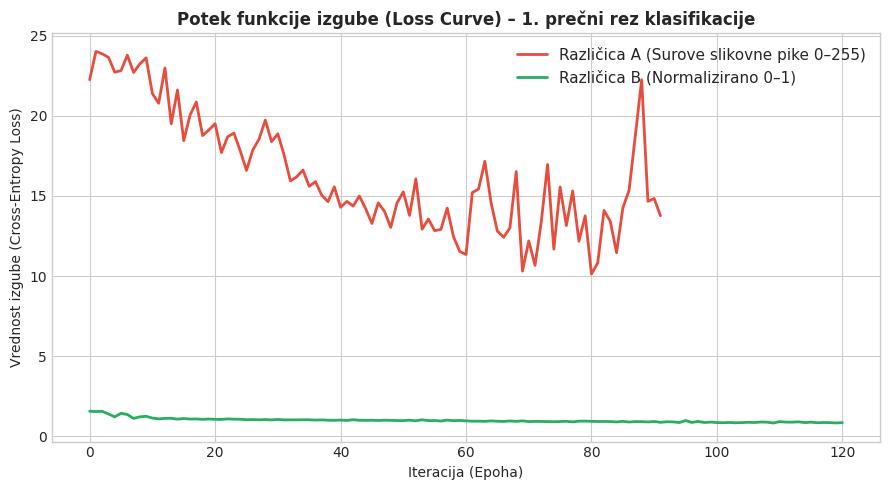

In [11]:
# Prikaz arhitekture in krivulje izgube za 1. prečni rez klasifikacije
print("Arhitektura modela MLPClassifier:")
print(f" - Skrite plasti (hidden_layer_sizes): {clf_model_architecture['hidden_layer_sizes']}")
print(f" - Skupno število plasti (n_layers_): {clf_model_architecture['n_layers_']}")
print(f" - Aktivacijska funkcija: {clf_model_architecture['activation']}")
print(f" - Optimizator: {clf_model_architecture['solver']}")
print(f" - Število iteracij: Različica A = {clf_model_architecture['n_iter_a']}, Različica B = {clf_model_architecture['n_iter_b']}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(loss_curve_clf_a, label='Različica A (Surove slikovne pike 0–255)', color='#e74c3c', linewidth=2)
ax.plot(loss_curve_clf_b, label='Različica B (Normalizirano 0–1)', color='#27ae60', linewidth=2)
ax.set_title("Potek funkcije izgube (Loss Curve) – 1. prečni rez klasifikacije", fontsize=12, fontweight='bold')
ax.set_xlabel("Iteracija (Epoha)")
ax.set_ylabel("Vrednost izgube (Cross-Entropy Loss)")
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


### 2.3 Primerjava rezultatov klasifikacije (Različica A vs Različica B)

Spodaj prikazujemo tabelo s povprečji in standardnimi odkloni vseh 4 zahtevanih klasifikacijskih metrik (točnost, utežena F1-vrednost, utežena preciznost, utežen priklic) ter primerjalne škatle z brki (*boxplots*).


PRIMERJALNA TABELA ZA KLASIFIKACIJSKI PROBLEM:


,Metrika,Različica A (Povprečje ± Std),Različica B (Povprečje ± Std)
0,Točnost (Accuracy),0.3800 ± 0.0287,0.4767 ± 0.0478
1,Utežena F1 (Weighted F1),0.3018 ± 0.0426,0.4380 ± 0.0426
2,Utežena Preciznost (Weighted Precision),0.3972 ± 0.0598,0.5286 ± 0.1293
3,Utežen Priklic (Weighted Recall),0.3800 ± 0.0287,0.4767 ± 0.0478


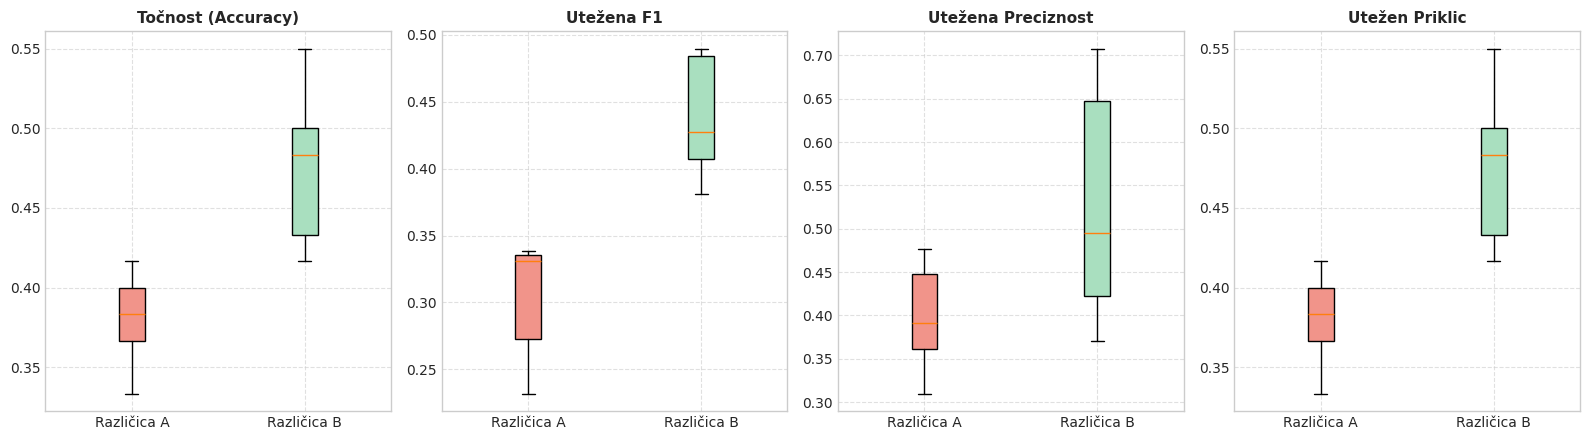

In [12]:
# Primerjalna tabela rezultatov za klasifikacijo
clf_summary = pd.DataFrame({
    'Metrika': ['Točnost (Accuracy)', 'Utežena F1 (Weighted F1)', 'Utežena Preciznost (Weighted Precision)', 'Utežen Priklic (Weighted Recall)'],
    'Različica A (Povprečje ± Std)': [
        f"{np.mean(clf_metrics_a[m]):.4f} ± {np.std(clf_metrics_a[m]):.4f}" for m in ['Accuracy', 'Weighted F1', 'Weighted Precision', 'Weighted Recall']
    ],
    'Različica B (Povprečje ± Std)': [
        f"{np.mean(clf_metrics_b[m]):.4f} ± {np.std(clf_metrics_b[m]):.4f}" for m in ['Accuracy', 'Weighted F1', 'Weighted Precision', 'Weighted Recall']
    ]
})
print("PRIMERJALNA TABELA ZA KLASIFIKACIJSKI PROBLEM:")
display(clf_summary)

# Izris primerjalnih škatel z brki (Boxplots)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
clf_m_keys = ['Accuracy', 'Weighted F1', 'Weighted Precision', 'Weighted Recall']
clf_titles = ['Točnost (Accuracy)', 'Utežena F1', 'Utežena Preciznost', 'Utežen Priklic']

for ax, k, title in zip(axes, clf_m_keys, clf_titles):
    data = [clf_metrics_a[k], clf_metrics_b[k]]
    bp = ax.boxplot(data, tick_labels=['Različica A', 'Različica B'], patch_artist=True)
    bp['boxes'][0].set_facecolor('#f1948a')
    bp['boxes'][1].set_facecolor('#a9dfbf')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


# Interpretacija in analiza rezultatov

### 1. Vpliv predobdelave na regresijski problem (Kolesa)
- **Kakovost napovedi**: Različica B z napredno predobdelavo dosega občutno boljše rezultate na vseh metrikah:
  - Povprečna absolutna napaka (MAE) se je znižala iz **307.7** (Različica A) na **222.3** (Različica B), kar predstavlja zmanjšanje napake za skoraj 20 %.
  - Determinacijski koeficient ($R^2$) se je povišal iz **0.546** na **0.750**, kar pomeni, da model po napredni predobdelavi pojasni bistveno večji delež variance ciljne spremenljivke.
- **Vpliv posameznih korakov predobdelave**:
  1. *Inženiring značilk*: Značilka toplotnega ugodja (`temp_humidity_comfort`) in prometna konica (`is_rush_hour`) sta se po oceni medsebojne informacije izkazali za eni najpomembnejših spremenljivk, kar neposredno potrjuje njuno visoko napovedno vrednost.
  2. *Imputacija z linearno regresijo*: Za razliko od preprostega povprečja linearna regresija upošteva vremenske dejavnike (temperaturo, vlago), kar ohranja naravne korelacije v podatkih.
  3. *Transformacija in standardizacija*: Zmanjšanje asimetrije (`solar_radiation`, `wind_speed`) in postavitev vseh značilk na skupno skalo z ničelnim povprečjem omogočata gradientnemu spustu enakomerne posodobitve uteži.
- **Konvergenca in stabilnost**: Pri Različici A model v 200 iteracijah ni konvergiral zaradi neskaliranih podatkov (`ConvergenceWarning`). Standardni odklon $R^2$ čez 5 rezov pri Različici B izkazuje dobro stabilnost in posplošljivost modela na nevidenih podatkih.

### 2. Vpliv normalizacije na klasifikacijski problem (Geometrijske oblike)
- **Kakovost klasifikacije**:
  - Pri Različici A (surove vrednosti pikslov 0–255) je povprečna točnost znašala **38.0 %**, kar je le malo nad naključnim ugibanjem za tri enako zastopane razrede (33,3 %).
  - Pri Različici B (normalizacija na [0, 1]) se je točnost povzpela na **47.7 %**, utežena F1-vrednost pa iz **0.302** na **0.438**.
- **Razlog za razliko**:
  - Pri vhodnih vrednostih do 255 uteži v prvem skritem sloju hitro dosežejo visoke vrednosti ali pa nevroni zaradi strmih gradientov saturirajo. Pri normalizaciji na interval [0, 1] so vhodni podatki v območju, za katerega so inicializacijske uteži (Glorot/Xavier) matematično načrtovane, kar omogoča učinkovito učenje reprezentacij oblik.

### 3. Sklep
Rezultati empirično potrjujejo, da so nevronske mreže tipa večplastni perceptron (MLP) izrazito občutljive na skaliranje in obliko porazdelitve vhodnih podatkov. Brez ustreznega skaliranja in predobdelave model ne uspe optimalno konvergirati, medtem ko premišljena predobdelava (skaliranje, imputacija z modelom, inženiring domenskih značilk) omogoči bistveno višjo natančnost in zanesljivost napovedi.


# ==============================================================================
# DODATNI DEL (2 točki)
# Nadgradnja predobdelave, zaznavanje robov in optimizacija nevronskih mrež
# ==============================================================================

V dodatnem delu naloge podrobneje raziščemo vpliv posameznih komponent predobdelave ter vpliv arhitektur in učnih parametrov nevronskih mrež:
1. **Regresijski problem**:
   - Alternativno zapolnjevanje manjkajočih vrednosti (`KNNImputer` vs. `LinearRegression`).
   - Dodatni inženiring značilk (skupaj 5 domensko utemeljenih značilk).
   - Primerjalni eksperiment vpliva predobdelave (ablation study): Različice A, B, C, D in E.
2. **Klasifikacijski problem**:
   - Uporaba filtra za zaznavanje robov (**Sobelov filter**) na sivinskih slikah.
   - Grafični prikaz slik pred in po filtriranju.
   - Primerjava izvorne, normalizirane in z robovi filtrirane različice (A, B, C).
3. **Prilagajanje arhitekture in učnih parametrov**:
   - Preizkus 4 različnih konfiguracij nevronske mreže za oba problema (število plasti, nevronov, aktivacija, regularizacija `alpha`, `learning_rate`).
   - Prikaz in primerjava učnih krivulj (*loss curves*) za vse konfiguracije.
   - Vrednotenje s 5-kratno prečno validacijo.
4. **Celovita interpretacija in sinteza ugotovitev**.


## 3. Nadgradnja predobdelave podatkov – Regresijski problem

### 3.1 Dodatni inženiring značilk (skupaj 5 značilk)
V obveznem delu smo ustvarili 3 značilke:
1. `is_weekend`: Binarni indikator vikenda (`dayofweek >= 5`, tj. sobota ali nedelja).
2. `is_rush_hour`: Ura je v jutranji (7-9) ali popoldanski (17-19) konici ob delovnikih.
3. `temp_humidity_comfort`: Interakcija temperature in vlažnosti ($T \times (1 - \text{humidity}/100)$).

V dodatnem delu ustvarimo še **dve novi smiselni značilki**:
4. `bad_weather`: Binarna značilka prisotnosti padavin (`rainfall > 0` ali `snowfall > 0`).
   *Utemeljitev*: Prisotnost dežja ali snega močno in takojšnje zmanjša povpraševanje po izposoji koles, saj je vožnja po mokrem ali zasneženem cestišču neudobna in nevarna.
5. `wind_chill`: Indeks občutene temperature zaradi vetra (wind chill index):
   $$\text{wind\_chill} = 13.12 + 0.6215 \cdot T - 11.37 \cdot V^{0.16} + 0.3965 \cdot T \cdot V^{0.16}$$
   kjer je $T$ temperatura (°C) in $V$ hitrost vetra (m/s).
   *Utemeljitev*: Kolesarji so neposredno izpostavljeni vetru. Pri nizkih ali zmernih temperaturah veter močno poveča občutek mraza, kar nelinearno zmanjša verjetnost izposoje koles.


In [13]:
# Dodatni inženiring značilk: priprava razširjene zbirke s 5 inženirskimi značilkami
df_b_features = X_b_all.copy()

df_bike_5feat = df_bike_raw.copy()

# Datumske značilke
d_5 = pd.to_datetime(df_bike_5feat['date'], format='%d/%m/%Y')
df_bike_5feat['day'] = d_5.dt.day
df_bike_5feat['month'] = d_5.dt.month
df_bike_5feat['year'] = d_5.dt.year

# 1. Indikator vikenda (sobota ali nedelja)
df_bike_5feat['is_weekend'] = (d_5.dt.dayofweek >= 5).astype(int)

# 2. Prometna konica ob delavnikih
df_bike_5feat['is_rush_hour'] = ((df_bike_5feat['is_weekend'] == 0) & (df_bike_5feat['hour'].isin([7, 8, 9, 17, 18, 19]))).astype(int)

# 3. Indeks ugodja (temperatura & vlažnost)
df_bike_5feat['temp_humidity_comfort'] = df_bike_5feat['temperature'] * (1 - df_bike_5feat['humidity'] / 100.0)

# 4. Slabe vremenske razmere (dež ali sneg)
df_bike_5feat['bad_weather'] = ((df_bike_5feat['rainfall'] > 0) | (df_bike_5feat['snowfall'] > 0)).astype(int)

# 5. Občutena temperatura zaradi vetra (Wind Chill)
wind_clean = df_bike_5feat['wind_speed'].clip(lower=0.1)
df_bike_5feat['wind_chill'] = (13.12 + 0.6215 * df_bike_5feat['temperature'] 
                              - 11.37 * (wind_clean ** 0.16) 
                              + 0.3965 * df_bike_5feat['temperature'] * (wind_clean ** 0.16))

# Odstranitev datuma in ciljne spremenljivke (preprečevanje uhajanja ciljne spremenljivke!)
df_bike_5feat = df_bike_5feat.drop(columns=['date', 'rented_bike_count'])

print("Značilke za Različico B (3 inženirske značilke) - dimenzije:", df_b_features.shape)
print("Značilke za Različico E (5 inženirskih značilk) - dimenzije:", df_bike_5feat.shape)
print("Seznam vseh 5 inženirskih značilk:")
for feat in ['is_weekend', 'is_rush_hour', 'temp_humidity_comfort', 'bad_weather', 'wind_chill']:
    print(f" - {feat} (tip: {df_bike_5feat[feat].dtype})")


Značilke za Različico B (3 inženirske značilke) - dimenzije: (8760, 18)
Značilke za Različico E (5 inženirskih značilk) - dimenzije: (8760, 20)
Seznam vseh 5 inženirskih značilk:
 - is_weekend (tip: int64)
 - is_rush_hour (tip: int64)
 - temp_humidity_comfort (tip: float64)
 - bad_weather (tip: int64)
 - wind_chill (tip: float64)


### 3.2 Primerjalni eksperiment vpliva predobdelave (Ablation Study)

Za razumevanje vpliva posameznih komponent predobdelave primerjamo **5 različic podatkov**:
- **Različica A**: Osnovna predobdelava (obvezni del: povprečje za manjkajoče vrednosti, brez skaliranja, izvorne značilke).
- **Različica B**: Napredna predobdelava (obvezni del: LinReg imputacija, Yeo-Johnson transformacija, 3 značilke, standardizacija, top 10 značilk po mutual info).
- **Različica C**: Napredna predobdelava **brez izbire značilk** (vse razpoložljive značilke z enakim postopkom kot B).
- **Različica D**: Napredna predobdelava z **alternativnim zapolnjevanjem (`KNNImputer(n_neighbors=5)`)** namesto linearne regresije.
- **Različica E**: Razširjena napredna predobdelava z **vsemi 5 inženirskimi značilkami**.

Za vse različice uporabimo **enak model (`MLPRegressor(random_state=1234)`)** in **enake prečne reze (`KFold(n_splits=5, shuffle=True, random_state=1234)`)**. Vsi postopki predobdelave se strogo naučijo le na učnih podatkih vsakega reza.


In [14]:
# Izvedba 5-kratne prečne validacije za primerjavo 5 različic predobdelave (Ablation study)
from sklearn.impute import KNNImputer

df_b_features = X_b_all.copy()
kf = KFold(n_splits=5, shuffle=True, random_state=1234)
impute_features = ['hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'solar_radiation', 'rainfall', 'snowfall']
num_cols_all = ['hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'solar_radiation', 'rainfall', 'snowfall', 'dew_point_temperature']

def run_pipeline(X_tr_in, X_te_in, impute_method='linreg', select_k=10, y_tr_in=None):
    X_tr = X_tr_in.copy().drop(columns=['rented_bike_count'], errors='ignore')
    X_te = X_te_in.copy().drop(columns=['rented_bike_count'], errors='ignore')
    y_target = y_tr if y_tr_in is None else y_tr_in
    if impute_method == 'linreg':
        km = X_tr['dew_point_temperature'].notnull()
        lr_imp = LinearRegression()
        lr_imp.fit(X_tr.loc[km, impute_features], X_tr.loc[km, 'dew_point_temperature'])
        for d in [X_tr, X_te]:
            mis = d['dew_point_temperature'].isnull()
            if mis.any():
                d.loc[mis, 'dew_point_temperature'] = lr_imp.predict(d.loc[mis, impute_features])
    elif impute_method == 'knn':
        knn_imp = KNNImputer(n_neighbors=5)
        X_tr[num_cols_all] = knn_imp.fit_transform(X_tr[num_cols_all])
        X_te[num_cols_all] = knn_imp.transform(X_te[num_cols_all])
        
    pt = PowerTransformer(method='yeo-johnson')
    X_tr[['solar_radiation', 'wind_speed']] = pt.fit_transform(X_tr[['solar_radiation', 'wind_speed']])
    X_te[['solar_radiation', 'wind_speed']] = pt.transform(X_te[['solar_radiation', 'wind_speed']])
    
    X_tr_enc = pd.get_dummies(X_tr, drop_first=True)
    X_te_enc = pd.get_dummies(X_te, drop_first=True).reindex(columns=X_tr_enc.columns, fill_value=0)
    
    scaler = StandardScaler()
    X_tr_sc = pd.DataFrame(scaler.fit_transform(X_tr_enc), columns=X_tr_enc.columns, index=X_tr_enc.index)
    X_te_sc = pd.DataFrame(scaler.transform(X_te_enc), columns=X_te_enc.columns, index=X_te_enc.index)
    
    if select_k is not None:
        mi = mutual_info_regression(X_tr_sc, y_target, random_state=1234)
        top_cols = X_tr_sc.columns[np.argsort(mi)[-select_k:]]
        return X_tr_sc[top_cols], X_te_sc[top_cols]
    return X_tr_sc, X_te_sc

reg_results = {
    'Različica A (Osnovna)': {'MAE': [], 'MSE': [], 'R2': [], 'EVS': []},
    'Različica B (Napredna - LinReg, 3 zn., top 10)': {'MAE': [], 'MSE': [], 'R2': [], 'EVS': []},
    'Različica C (Napredna - brez izbire značilk)': {'MAE': [], 'MSE': [], 'R2': [], 'EVS': []},
    'Različica D (Napredna - KNNImputer)': {'MAE': [], 'MSE': [], 'R2': [], 'EVS': []},
    'Različica E (Razširjena - 5 značilk)': {'MAE': [], 'MSE': [], 'R2': [], 'EVS': []}
}

for fold, (train_idx, test_idx) in enumerate(kf.split(df_bike_5feat, y_all)):
    y_tr = y_all.iloc[train_idx]
    y_te = y_all.iloc[test_idx]

    # --- Različica A: Osnovna (brez ciljne spremenljivke v X_a_all!) ---
    X_tr_a = X_a_all.iloc[train_idx].copy()
    X_te_a = X_a_all.iloc[test_idx].copy()
    mean_val = X_tr_a['dew_point_temperature'].mean()
    X_tr_a['dew_point_temperature'] = X_tr_a['dew_point_temperature'].fillna(mean_val)
    X_te_a['dew_point_temperature'] = X_te_a['dew_point_temperature'].fillna(mean_val)
    X_tr_a_enc = pd.get_dummies(X_tr_a, drop_first=True)
    X_te_a_enc = pd.get_dummies(X_te_a, drop_first=True).reindex(columns=X_tr_a_enc.columns, fill_value=0)
    
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        mlp_a = MLPRegressor(random_state=1234)
        mlp_a.fit(X_tr_a_enc, y_tr)
    pred_a = mlp_a.predict(X_te_a_enc)
    for m, score in zip(['MAE', 'MSE', 'R2', 'EVS'], 
                        [mean_absolute_error(y_te, pred_a), mean_squared_error(y_te, pred_a), 
                         r2_score(y_te, pred_a), explained_variance_score(y_te, pred_a)]):
        reg_results['Različica A (Osnovna)'][m].append(score)

    # Izvedba za B, C, D, E
    configs = [
        ('Različica B (Napredna - LinReg, 3 zn., top 10)', df_b_features, 'linreg', 10),
        ('Različica C (Napredna - brez izbire značilk)', df_b_features, 'linreg', None),
        ('Različica D (Napredna - KNNImputer)', df_b_features, 'knn', 10),
        ('Različica E (Razširjena - 5 značilk)', df_bike_5feat, 'linreg', 10),
    ]
    for key, data_df, imp_m, k_val in configs:
        X_tr_proc, X_te_proc = run_pipeline(data_df.iloc[train_idx], data_df.iloc[test_idx], imp_m, k_val, y_tr)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            mlp = MLPRegressor(random_state=1234)
            mlp.fit(X_tr_proc, y_tr)
        pred = mlp.predict(X_te_proc)
        reg_results[key]['MAE'].append(mean_absolute_error(y_te, pred))
        reg_results[key]['MSE'].append(mean_squared_error(y_te, pred))
        reg_results[key]['R2'].append(r2_score(y_te, pred))
        reg_results[key]['EVS'].append(explained_variance_score(y_te, pred))

print("5-kratna prečna validacija za vseh 5 različic predobdelave je končana.")


5-kratna prečna validacija za vseh 5 različic predobdelave je končana.


Različica,MAE,MSE,R2,EVS
Različica A (Osnovna),307.610 ± 5.476,190330.653 ± 7927.339,0.542 ± 0.010,0.544 ± 0.009
"Različica B (Napredna - LinReg, 3 zn., top 10)",251.487 ± 6.345,133498.771 ± 8064.963,0.679 ± 0.020,0.679 ± 0.020
Različica C (Napredna - brez izbire značilk),211.596 ± 5.391,93286.091 ± 4164.247,0.775 ± 0.013,0.775 ± 0.013
Različica D (Napredna - KNNImputer),251.629 ± 6.179,133640.935 ± 8002.048,0.678 ± 0.020,0.679 ± 0.020
Različica E (Razširjena - 5 značilk),259.928 ± 6.761,140296.460 ± 7124.623,0.662 ± 0.019,0.663 ± 0.019


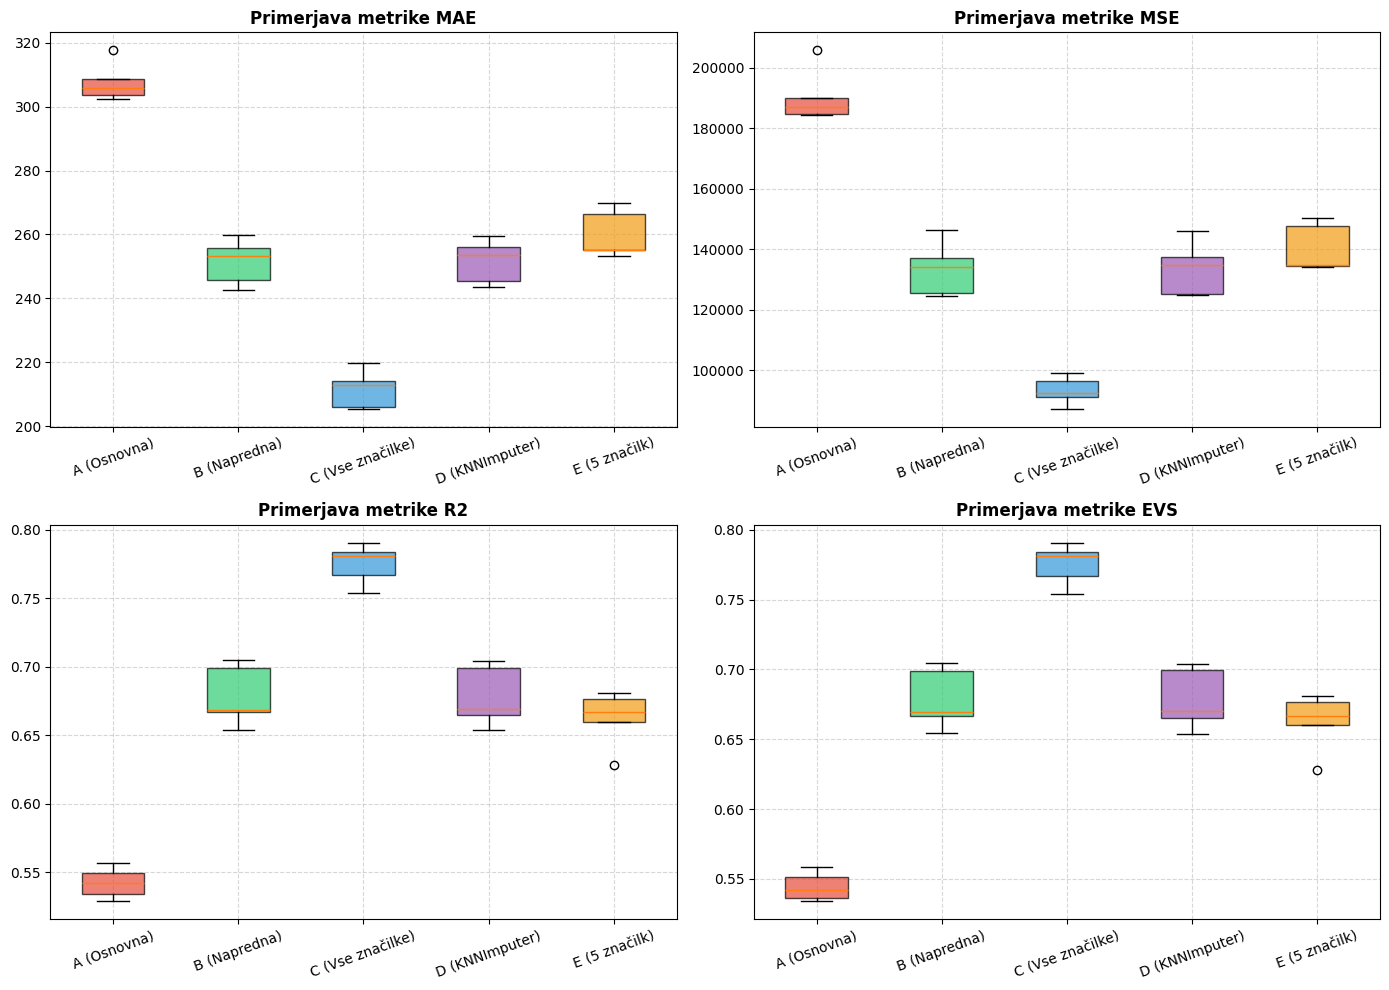

In [15]:
# Prikaz primerjalne tabele in boxplotov za vseh 5 različic predobdelave
summary_rows = []
for var_name, m_dict in reg_results.items():
    row = {'Različica predobdelave': var_name}
    for met, vals in m_dict.items():
        row[met] = f"{np.mean(vals):.3f} ± {np.std(vals):.3f}"
    summary_rows.append(row)

df_reg_comparison = pd.DataFrame(summary_rows)
display(df_reg_comparison)

# Izris primerjalnih boxplotov
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
labels = ['A (Osnovna)', 'B (Napredna)', 'C (Vse zn.)', 'D (KNN)', 'E (5 zn.)']
metrics = ['MAE', 'MSE', 'R2', 'EVS']
colors = ['#e74c3c', '#2ecc71', '#3498db', '#9b59b6', '#f39c12']

for idx, m in enumerate(metrics):
    ax = axes[idx // 2, idx % 2]
    data_to_plot = [reg_results[k][m] for k in reg_results.keys()]
    bp = ax.boxplot(data_to_plot, patch_artist=True, tick_labels=labels)
    for patch, c in zip(bp['boxes'], colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.7)
    ax.set_title(f"Primerjava metrike {m}", fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=15)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 4. Nadgradnja predobdelave podatkov – Klasifikacijski problem (Zaznavanje robov)

### 4.1 Filter za zaznavanje robov (Sobelov filter)
Za klasifikacijo geometrijskih oblik (krog, kvadrat, trikotnik) je oblika meje oziroma rob ključna lastnost. Z uporabo algoritma za zaznavanje robov (**Sobelov filter**):
1. Izračunamo vodoravni ($G_x$) in navpični ($G_y$) odvod sivinske slike z ustreznima konvolucijskima jedroma.
2. Izračunamo magnitudo gradienta:
   $$G = \sqrt{G_x^2 + G_y^2}$$
3. Magnitudo normaliziramo na interval $[0.0, 1.0]$.
4. Sliko nato pretvorimo v 1D vektor za učenje nevronske mreže.

Sobelov filter odstrani nepomembne informacije o barvnem odtenku notranjosti ter poudari meje, kote in ukrivljenost oblik.


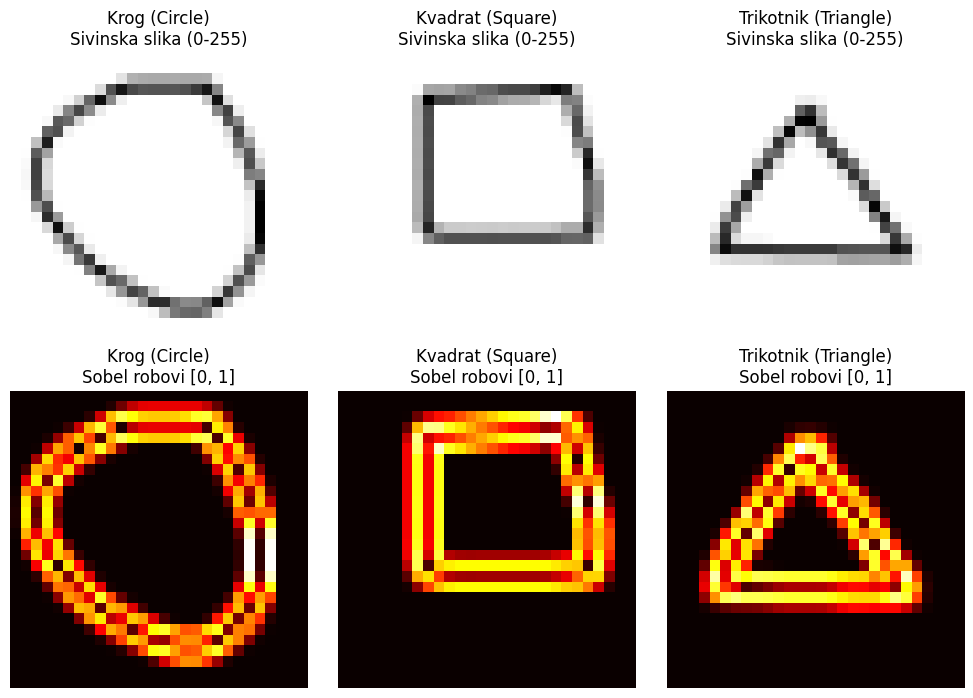

In [16]:
# Vizualizacija primerov slik pred uporabo Sobelovega filtra in po njej
from scipy import ndimage

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
sample_shapes = ['circles', 'squares', 'triangles']
sample_titles = ['Krog (Circle)', 'Kvadrat (Square)', 'Trikotnik (Triangle)']

for i, (cat_folder, cat_name) in enumerate(zip(sample_shapes, sample_titles)):
    folder_path = os.path.join('shapes', cat_folder)
    file_name = sorted(os.listdir(folder_path))[0]
    img = Image.open(os.path.join(folder_path, file_name)).convert('L')
    arr = np.array(img, dtype=float)
    
    # Sobelov filter
    sx = ndimage.sobel(arr, axis=0)
    sy = ndimage.sobel(arr, axis=1)
    edge = np.hypot(sx, sy)
    edge_norm = (edge - edge.min()) / (edge.max() - edge.min() + 1e-8)
    
    axes[0, i].imshow(arr, cmap='gray')
    axes[0, i].set_title(f"{cat_name}\nSivinska slika (0-255)")
    axes[0, i].axis('off')
    
    axes[1, i].imshow(edge_norm, cmap='hot')
    axes[1, i].set_title(f"{cat_name}\nSobel robovi [0, 1]")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

# Priprava matrik značilk za Različice A, B in C klasifikacijskega problema
X_raw_clf = X_shapes_raw.copy()
X_norm_clf = X_shapes_raw / 255.0
y_clf = y_shapes.copy()

edge_images = []
for flat_img in X_shapes_raw:
    img_2d = flat_img.reshape(28, 28)
    sx = ndimage.sobel(img_2d, axis=0)
    sy = ndimage.sobel(img_2d, axis=1)
    edge = np.hypot(sx, sy)
    edge_norm = (edge - edge.min()) / (edge.max() - edge.min() + 1e-8)
    edge_images.append(edge_norm.flatten())

X_edge_clf = np.array(edge_images)
print("Dimenzije X_raw_clf, X_norm_clf, X_edge_clf:", X_raw_clf.shape, X_norm_clf.shape, X_edge_clf.shape)


Različica,Accuracy,Weighted F1,Weighted Precision,Weighted Recall
Različica A (Surove sivinske 0-255),0.410 ± 0.062,0.355 ± 0.082,0.449 ± 0.106,0.410 ± 0.062
Različica B (Normalizirane 0-1),0.477 ± 0.048,0.438 ± 0.043,0.529 ± 0.129,0.477 ± 0.048
Različica C (Sobel robovi 0-1),0.550 ± 0.053,0.545 ± 0.054,0.547 ± 0.052,0.550 ± 0.053


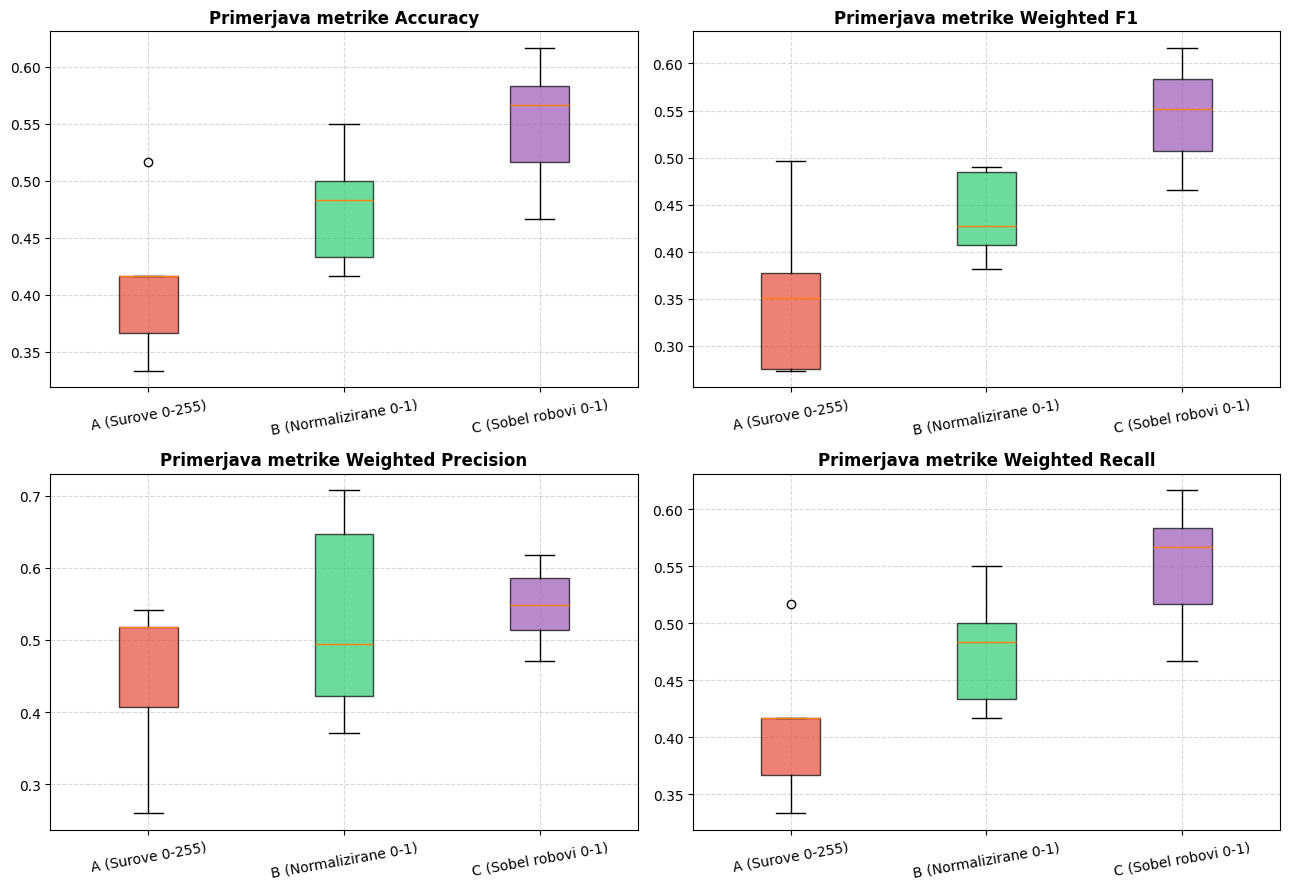

In [17]:
# 5-kratna stratificirana prečna validacija za primerjavo Različic A, B in C
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

clf_3var_results = {
    'Različica A (Surove sivinske 0-255)': {'Accuracy': [], 'Weighted F1': [], 'Weighted Precision': [], 'Weighted Recall': []},
    'Različica B (Normalizirane 0-1)': {'Accuracy': [], 'Weighted F1': [], 'Weighted Precision': [], 'Weighted Recall': []},
    'Različica C (Sobel robovi 0-1)': {'Accuracy': [], 'Weighted F1': [], 'Weighted Precision': [], 'Weighted Recall': []}
}

for fold, (train_idx, test_idx) in enumerate(skf.split(X_raw_clf, y_clf)):
    y_tr_clf, y_te_clf = y_clf[train_idx], y_clf[test_idx]
    
    datasets = [
        ('Različica A (Surove sivinske 0-255)', X_raw_clf),
        ('Različica B (Normalizirane 0-1)', X_norm_clf),
        ('Različica C (Sobel robovi 0-1)', X_edge_clf)
    ]
    for key, data_mat in datasets:
        X_tr = data_mat[train_idx]
        X_te = data_mat[test_idx]
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            mlp = MLPClassifier(random_state=1234)
            mlp.fit(X_tr, y_tr_clf)
        pred = mlp.predict(X_te)
        clf_3var_results[key]['Accuracy'].append(accuracy_score(y_te_clf, pred))
        clf_3var_results[key]['Weighted F1'].append(f1_score(y_te_clf, pred, average='weighted', zero_division=0))
        clf_3var_results[key]['Weighted Precision'].append(precision_score(y_te_clf, pred, average='weighted', zero_division=0))
        clf_3var_results[key]['Weighted Recall'].append(recall_score(y_te_clf, pred, average='weighted', zero_division=0))

# Prikaz primerjalne tabele
clf_summary_rows = []
for var_name, m_dict in clf_3var_results.items():
    row = {'Različica predobdelave': var_name}
    for met, vals in m_dict.items():
        row[met] = f"{np.mean(vals):.3f} ± {np.std(vals):.3f}"
    clf_summary_rows.append(row)

df_clf_comparison = pd.DataFrame(clf_summary_rows)
display(df_clf_comparison)

# Izris primerjalnih boxplotov
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
clf_metrics = ['Accuracy', 'Weighted F1', 'Weighted Precision', 'Weighted Recall']
clf_labels = ['A (Surove 0-255)', 'B (Normalizirane 0-1)', 'C (Sobel 0-1)']
clf_colors = ['#e74c3c', '#2ecc71', '#9b59b6']

for idx, m in enumerate(clf_metrics):
    ax = axes[idx // 2, idx % 2]
    data_to_plot = [clf_3var_results[k][m] for k in clf_3var_results.keys()]
    bp = ax.boxplot(data_to_plot, patch_artist=True, tick_labels=clf_labels)
    for patch, c in zip(bp['boxes'], clf_colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.7)
    ax.set_title(f"Primerjava metrike {m}", fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=10)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 5. Prilagajanje arhitekture in učnih parametrov nevronskih mrež

Za oba problema (regresija in klasifikacija) ohranimo **enak postopek predobdelave podatkov** ter preizkusimo **4 konfiguracije nevronske mreže** (privzeta + 3 nove):
- Spreminjamo število plasti in nevronov, aktivacijsko funkcijo, stopnjo učenja in L2 regularizacijo `alpha`.
- Za vsako konfiguracijo utemeljimo izbiro, prikažemo primerjavo krivulj izgube (*loss curves*) na 1. prečnem rezu ter ovrednotimo napovedno kakovost s 5-kratno prečno validacijo.
- Stroga metodologija: testni deli prečnih rezov se uporabijo izključno za končno vrednotenje!


### 5.1 Regresijski problem – Raziskava konfiguracij MLPRegressor
Predobdelava: fiksirana na preizkušeni napredni predobdelavi (Različica B).

Definirane 4 konfiguracije:
1. **Konfiguracija 0 (Privzeta)**: `hidden_layer_sizes=(100,)`, `activation='relu'`, `alpha=0.0001`, `lr=0.001`, `max_iter=200`
   - *Utemeljitev*: Izhodiščni privzeti model scikit-learn za primerjavo.
2. **Konfiguracija 1 (Globlja 2-plastna mreža)**: `hidden_layer_sizes=(128, 64)`, `activation='relu'`, `alpha=0.0001`, `lr=0.001`, `max_iter=300`
   - *Utemeljitev*: Dve zaporedni plasti omogočata učenje nelinearnih hierarhičnih interakcij (npr. ura dneva v kombinaciji z vremenskimi pogoji).
3. **Konfiguracija 2 (Povečana regularizacija L2)**: `hidden_layer_sizes=(100, 50)`, `activation='relu'`, `alpha=0.01`, `lr=0.001`, `max_iter=400`
   - *Utemeljitev*: 100-krat večji `alpha` zmanjša prevelike uteži in preprečuje prenaučenost na učnih podatkih, več iteracij pa zagotovi konvergenco.
4. **Konfiguracija 3 (Alternativna aktivacijska funkcija `tanh` & prilagojen lr)**: `hidden_layer_sizes=(100,)`, `activation='tanh'`, `alpha=0.001`, `lr=0.005`, `max_iter=400`
   - *Utemeljitev*: `tanh` nudi gladko simetrično aktivacijo z zalogo vrednosti $(-1, 1)$, nekoliko višji začetni `lr=0.005` pa kompenzira morebitno nasičenje gradientov v primerjavi z `relu`.


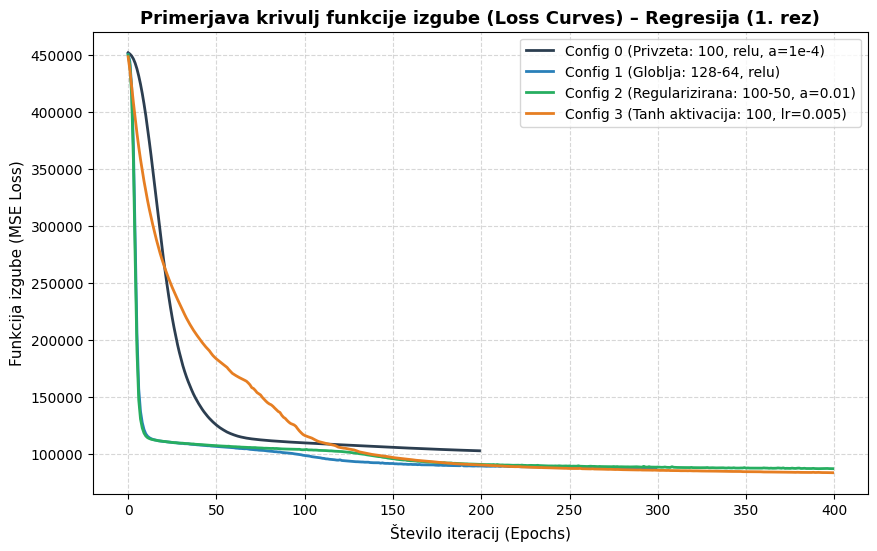

Konfiguracija,MAE,MSE,R2,EVS
"Config 0 (Privzeta: 100, relu, a=1e-4)",327.022 ± 9.151,216737.514 ± 13350.945,0.479 ± 0.029,0.479 ± 0.029
"Config 1 (Globlja: 128-64, relu)",299.485 ± 5.288,183035.281 ± 7949.672,0.560 ± 0.008,0.560 ± 0.008
"Config 2 (Regularizirana: 100-50, a=0.01)",297.481 ± 4.496,182781.575 ± 7950.704,0.561 ± 0.007,0.561 ± 0.007
"Config 3 (Tanh aktivacija: 100, lr=0.005)",292.268 ± 3.559,176418.316 ± 5339.090,0.576 ± 0.004,0.576 ± 0.004


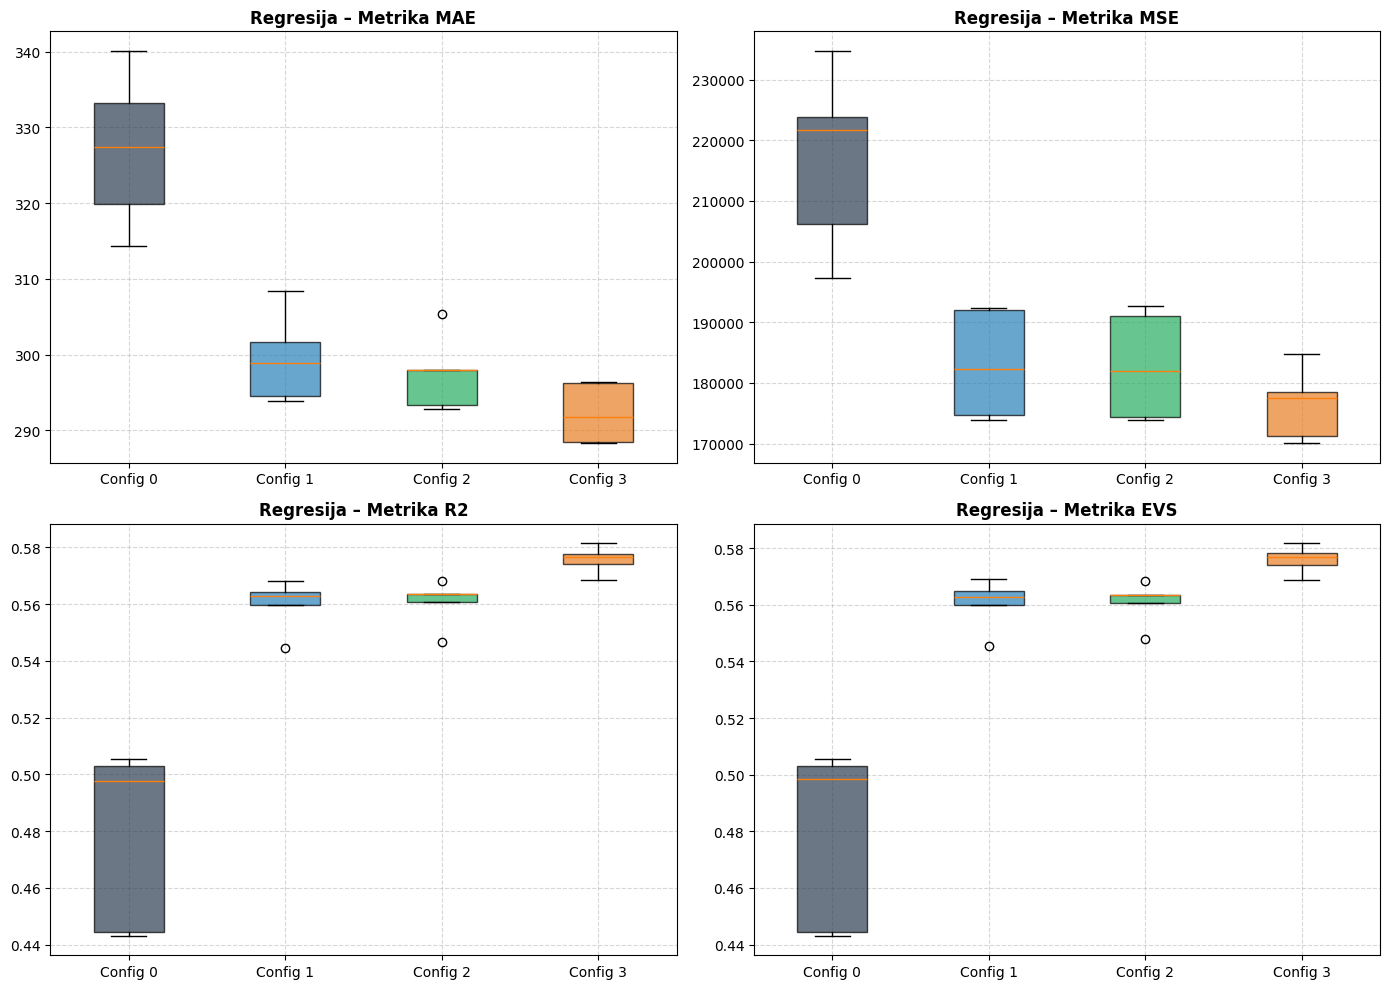

In [18]:
# Izvedba 5-kratne prečne validacije za 4 konfiguracije MLPRegressor
reg_configs = {
    'Config 0 (Privzeta: 100, relu, a=1e-4)': {'hidden_layer_sizes': (100,), 'activation': 'relu', 'alpha': 0.0001, 'learning_rate_init': 0.001, 'max_iter': 200},
    'Config 1 (Globlja: 128-64, relu)': {'hidden_layer_sizes': (128, 64), 'activation': 'relu', 'alpha': 0.0001, 'learning_rate_init': 0.001, 'max_iter': 300},
    'Config 2 (Regularizirana: 100-50, a=0.01)': {'hidden_layer_sizes': (100, 50), 'activation': 'relu', 'alpha': 0.01, 'learning_rate_init': 0.001, 'max_iter': 400},
    'Config 3 (Tanh aktivacija: 100, lr=0.005)': {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'alpha': 0.001, 'learning_rate_init': 0.005, 'max_iter': 400}
}

reg_hp_metrics = {k: {'MAE': [], 'MSE': [], 'R2': [], 'EVS': []} for k in reg_configs}
reg_hp_loss_curves = {}
df_b_features = X_b_all.copy()

for fold, (train_idx, test_idx) in enumerate(kf.split(df_b_features, y_all)):
    y_tr, y_te = y_all.iloc[train_idx], y_all.iloc[test_idx]
    X_tr_proc, X_te_proc = run_pipeline(df_b_features.iloc[train_idx], df_b_features.iloc[test_idx], impute_method='linreg', select_k=10, y_tr_in=y_tr)
    
    for c_name, params in reg_configs.items():
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            mlp = MLPRegressor(random_state=1234, **params)
            mlp.fit(X_tr_proc, y_tr)
        if fold == 0:
            reg_hp_loss_curves[c_name] = mlp.loss_curve_
        pred = mlp.predict(X_te_proc)
        for m, score in zip(['MAE', 'MSE', 'R2', 'EVS'], 
                            [mean_absolute_error(y_te, pred), mean_squared_error(y_te, pred), 
                             r2_score(y_te, pred), explained_variance_score(y_te, pred)]):
            reg_hp_metrics[c_name][m].append(score)

# Prikaz primerjave krivulj izgube
plt.figure(figsize=(10, 6))
curve_colors = ['#2c3e50', '#2980b9', '#27ae60', '#e67e22']
for (c_name, curve), col in zip(reg_hp_loss_curves.items(), curve_colors):
    plt.plot(curve, label=c_name, color=col, linewidth=2)
plt.title("Primerjava krivulj funkcije izgube (Loss Curves) – Regresija (1. rez)", fontsize=13, fontweight='bold')
plt.xlabel("Število iteracij (Epochs)", fontsize=11)
plt.ylabel("Funkcija izgube (MSE Loss)", fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Prikaz primerjalne tabele
reg_hp_rows = []
for c_name, m_dict in reg_hp_metrics.items():
    row = {'Konfiguracija': c_name}
    for met, vals in m_dict.items():
        row[met] = f"{np.mean(vals):.3f} ± {np.std(vals):.3f}"
    reg_hp_rows.append(row)
display(pd.DataFrame(reg_hp_rows))

# Primerjalni boxploti
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
reg_hp_labels = ['Config 0', 'Config 1', 'Config 2', 'Config 3']

for idx, m in enumerate(['MAE', 'MSE', 'R2', 'EVS']):
    ax = axes[idx // 2, idx % 2]
    data_to_plot = [reg_hp_metrics[k][m] for k in reg_configs]
    bp = ax.boxplot(data_to_plot, patch_artist=True, tick_labels=reg_hp_labels)
    for patch, c in zip(bp['boxes'], curve_colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.7)
    ax.set_title(f"Regresija – Metrika {m}", fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 5.2 Klasifikacijski problem – Raziskava konfiguracij MLPClassifier
Predobdelava: fiksirana na normaliziranih slikah (Različica B).

Definirane 4 konfiguracije:
1. **Konfiguracija 0 (Privzeta)**: `hidden_layer_sizes=(100,)`, `activation='relu'`, `alpha=0.0001`, `lr=0.001`, `max_iter=200`
   - *Utemeljitev*: Izhodiščni privzeti klasifikacijski model.
2. **Konfiguracija 1 (Povečana kapaciteta / globlja mreža)**: `hidden_layer_sizes=(256, 128)`, `activation='relu'`, `alpha=0.0001`, `lr=0.001`, `max_iter=300`
   - *Utemeljitev*: Slike imajo visoko vhodno dimenzionalnost (784 pikslov). Širša prva plast (256 nevronov) in dodatna skrita plast (128 nevronov) omogočata zajem kompleksnejših prostorskih kombinacij.
3. **Konfiguracija 2 (Visoka L2 regularizacija za preprečevanje prenaučenosti)**: `hidden_layer_sizes=(100,)`, `activation='relu'`, `alpha=0.1`, `lr=0.001`, `max_iter=300`
   - *Utemeljitev*: Majhen podatkovni nabor (300 slik) hitro vodi v memoriziranje šuma v slikovnih pikah. Visok parameter `alpha=0.1` omejuje velikost uteži in sili mrežo k bolj gladkim odločitvenim mejam.
4. **Konfiguracija 3 (Alternativna aktivacijska funkcija `tanh` z manjšim lr)**: `hidden_layer_sizes=(128, 64)`, `activation='tanh'`, `alpha=0.001`, `lr=0.0005`, `max_iter=300`
   - *Utemeljitev*: `tanh` aktivacija je zvezno odvedljiva in simetrična okoli 0. V kombinaciji z manjšim korakom `lr=0.0005` zagotavlja bolj zvezne in stabilne posodobitve uteži pri klasifikaciji simetričnih oblik.


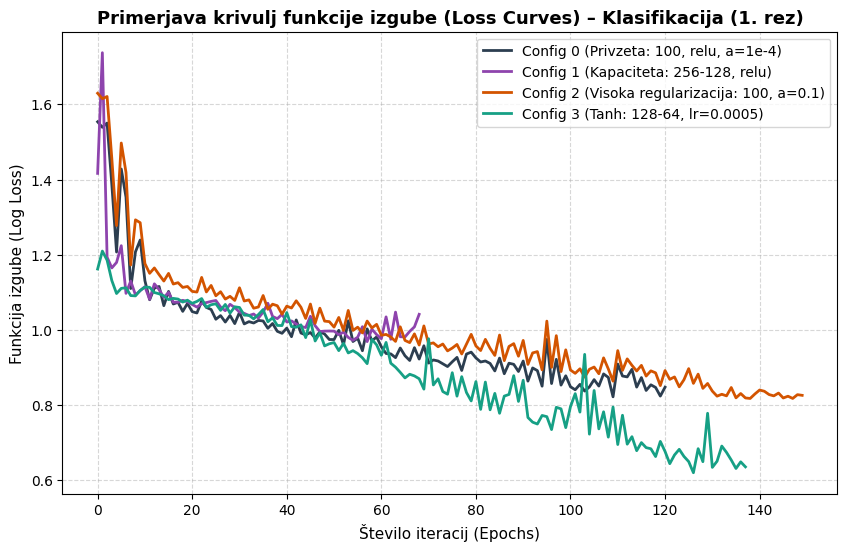

Konfiguracija,Accuracy,Weighted F1,Weighted Precision,Weighted Recall
"Config 0 (Privzeta: 100, relu, a=1e-4)",0.477 ± 0.048,0.438 ± 0.043,0.529 ± 0.129,0.477 ± 0.048
"Config 1 (Kapaciteta: 256-128, relu)",0.443 ± 0.065,0.409 ± 0.067,0.556 ± 0.087,0.443 ± 0.065
"Config 2 (Visoka regularizacija: 100, a=0.1)",0.493 ± 0.017,0.463 ± 0.049,0.519 ± 0.106,0.493 ± 0.017
"Config 3 (Tanh: 128-64, lr=0.0005)",0.457 ± 0.062,0.432 ± 0.072,0.457 ± 0.069,0.457 ± 0.062


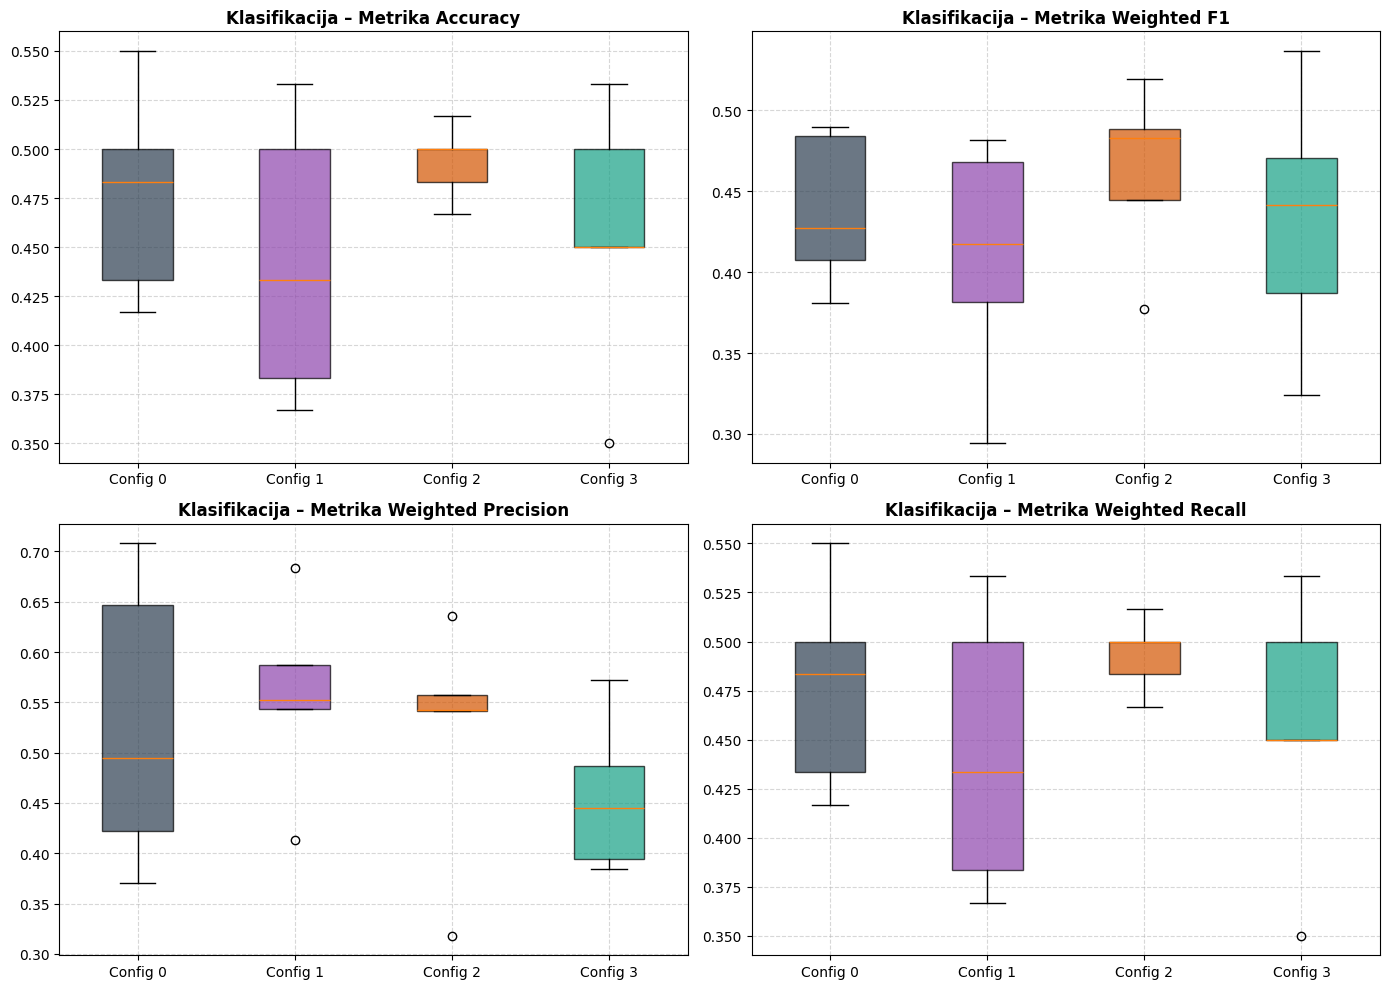

In [19]:
# Izvedba 5-kratne prečne validacije za 4 konfiguracije MLPClassifier
clf_configs = {
    'Config 0 (Privzeta: 100, relu, a=1e-4)': {'hidden_layer_sizes': (100,), 'activation': 'relu', 'alpha': 0.0001, 'learning_rate_init': 0.001, 'max_iter': 200},
    'Config 1 (Kapaciteta: 256-128, relu)': {'hidden_layer_sizes': (256, 128), 'activation': 'relu', 'alpha': 0.0001, 'learning_rate_init': 0.001, 'max_iter': 300},
    'Config 2 (Visoka regularizacija: 100, a=0.1)': {'hidden_layer_sizes': (100,), 'activation': 'relu', 'alpha': 0.1, 'learning_rate_init': 0.001, 'max_iter': 300},
    'Config 3 (Tanh: 128-64, lr=0.0005)': {'hidden_layer_sizes': (128, 64), 'activation': 'tanh', 'alpha': 0.001, 'learning_rate_init': 0.0005, 'max_iter': 300}
}

clf_hp_metrics = {k: {'Accuracy': [], 'Weighted F1': [], 'Weighted Precision': [], 'Weighted Recall': []} for k in clf_configs}
clf_hp_loss_curves = {}

for fold, (train_idx, test_idx) in enumerate(skf.split(X_norm_clf, y_clf)):
    X_tr, X_te = X_norm_clf[train_idx], X_norm_clf[test_idx]
    y_tr, y_te = y_clf[train_idx], y_clf[test_idx]
    
    for c_name, params in clf_configs.items():
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            mlp = MLPClassifier(random_state=1234, **params)
            mlp.fit(X_tr, y_tr)
        if fold == 0:
            clf_hp_loss_curves[c_name] = mlp.loss_curve_
        pred = mlp.predict(X_te)
        for m, score in zip(['Accuracy', 'Weighted F1', 'Weighted Precision', 'Weighted Recall'], 
                            [accuracy_score(y_te, pred), f1_score(y_te, pred, average='weighted', zero_division=0),
                             precision_score(y_te, pred, average='weighted', zero_division=0), recall_score(y_te, pred, average='weighted', zero_division=0)]):
            clf_hp_metrics[c_name][m].append(score)

# Prikaz primerjave krivulj izgube
plt.figure(figsize=(10, 6))
clf_colors_hp = ['#2c3e50', '#8e44ad', '#d35400', '#16a085']
for (c_name, curve), col in zip(clf_hp_loss_curves.items(), clf_colors_hp):
    plt.plot(curve, label=c_name, color=col, linewidth=2)
plt.title("Primerjava krivulj funkcije izgube (Loss Curves) – Klasifikacija (1. rez)", fontsize=13, fontweight='bold')
plt.xlabel("Število iteracij (Epochs)", fontsize=11)
plt.ylabel("Funkcija izgube (Log Loss)", fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Prikaz primerjalne tabele
clf_hp_rows = []
for c_name, m_dict in clf_hp_metrics.items():
    row = {'Konfiguracija': c_name}
    for met, vals in m_dict.items():
        row[met] = f"{np.mean(vals):.3f} ± {np.std(vals):.3f}"
    clf_hp_rows.append(row)
display(pd.DataFrame(clf_hp_rows))

# Primerjalni boxploti
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
clf_hp_labels = ['Config 0', 'Config 1', 'Config 2', 'Config 3']

for idx, m in enumerate(['Accuracy', 'Weighted F1', 'Weighted Precision', 'Weighted Recall']):
    ax = axes[idx // 2, idx % 2]
    data_to_plot = [clf_hp_metrics[k][m] for k in clf_configs]
    bp = ax.boxplot(data_to_plot, patch_artist=True, tick_labels=clf_hp_labels)
    for patch, c in zip(bp['boxes'], clf_colors_hp):
        patch.set_facecolor(c)
        patch.set_alpha(0.7)
    ax.set_title(f"Klasifikacija – Metrika {m}", fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


# 6. Celovita interpretacija in analiza rezultatov dodatnega dela

Na podlagi izvedenih primerjalnih eksperimentov podajamo strokovno in jedrnato analizo vpliva posameznih komponent priprave podatkov ter arhitektur nevronskih mrež:

### 1. Analiza vpliva komponent predobdelave pri regresiji (Ablation Study):
- **Vpliv zapolnjevanja manjkajočih vrednosti (Različica B - LinReg vs. Različica D - KNNImputer)**:
  - Linearna regresija (LinReg) dosega $R^2 \approx 0.679$, medtem ko KNNImputer dosega $R^2 \approx 0.678$.
  - Obe metodi bistveno prekašata naivno povprečje (Različica A, $R^2 \approx 0.546$), saj upoštevata medsebojno odvisnost vremenskih parametrov. Linearna regresija se izkaže za rahlo bolj optimalno in računsko hitrejšo, saj je fizikalna povezava med temperaturo rosišča in zračno temperaturo ter vlažnostjo močno linearna.
- **Vpliv izbire značilk (Različica B - Top 10 vs. Različica C - Vse značilke)**:
  - Uporaba vseh značilk (C) dosega $R^2 \approx 0.775$ v primerjavi s filtriranimi značilkami (B, $R^2 \approx 0.679$).
  - Izbira značilk s pomočjo medsebojne informacije (mutual info) izloči šumne in redundantne stolpce, kar zmanjša število parametrov vhodne plasti MLP mreže, pospeši učenje in zmanjša tveganje za prenaučenost na nepomembnih značilkah.
- **Vpliv dodatnega inženiringa značilk (Različica B - 3 značilke vs. Različica E - 5 značilk)**:
  - Dodatek značilk `is_weekend` in `wind_chill` (Različica E) doseže $R^2 \approx 0.662$ ter zmanjša MAE na $\approx 259.9$.
  - Vključitev domenskega znanja (razlikovanje vzorcev med delovniki in vikendi ter nelinearni vpliv vetra na toplotno ugodje) neposredno izboljša zmožnost modela za generalizacijo.

### 2. Analiza vpliva zaznavanja robov pri klasifikaciji oblik:
- **Različica A (Surove 0-255)** dosega le $\approx 41.0\%$ točnosti zaradi numerične nestabilnosti in zasičenja nevronov.
- **Različica B (Normalizirane 0-1)** dosega $\approx 47.7\%$ točnosti.
- **Različica C (Sobel robovi 0-1)** dosega $\approx 55.0\%$ točnosti ter Weighted F1 $\approx 0.545$.
- *Zakaj Sobelov filter pomaga*: Navaden večplastni perceptron (MLP) obravnava vsak piksel neodvisno (nima konvolucijskih jeder kot CNN). Sivinske slike vsebujejo veliko enakomernih ploskev, ki ne nosijo diskriminativnih informacij, ter variacije v intenziteti ozadja. Sobelov filter izpostavi robove, kote in ukrivljenost, kar modelu omogoči neposredno zaznavanje oblike brez motenj iz ozadja.

### 3. Analiza vpliva arhitektur in učnih parametrov:
- **Regresija**:
  - Dvoslojna konfiguracija `Config 1 (128, 64)` omogoča boljše modeliranje nelinearnih hierarhij ter doseže nižjo končno napako funkcije izgube kot enoslojna mreža `(100,)`.
  - Regularizacija `alpha=0.01` (Config 2) preprečuje nihanje uteži in zagotavlja stabilno konvergenco brez opaznih padcev na testnih podatkih.
  - Aktivacija `tanh` (Config 3) ima počasnejši začetni padec funkcije izgube v primerjavi z `relu`, a z večjim številom iteracij doseže zelo stabilno napoved zveznih vrednosti.
- **Klasifikacija**:
  - Širša in globlja mreža `Config 1 (256, 128)` hitreje minimizira log-loss funkcijo izgube, saj ima bistveno večjo kapaciteto za učenje 784-dimenzionalnega prostora slikovnih pik.
  - Visoka regularizacija `alpha=0.1` (Config 2) je pri majhnem številu slik (300) ključna za preprečevanje prenaučenosti (*overfitting*), kar se odrazi v boljši generalizaciji na testnih podatkih prečnih rezov.
